# Clusterização de imagens de glaucoma (HYGD)

**O que fazemos:** agrupamos as 737 imagens de fundo de olho (as 747 do dataset menos 10 cópias idênticas) **sem usar nenhum rótulo** e comparamos três formas de descrever cada imagem:

1. **Tradicional:** estatísticas calculadas direto nos pixels (cor, histogramas, nitidez, iluminação).
2. **Deep Learning:** *embeddings* da última camada escondida da MobileNetV3-Small (pré-treinada e congelada).
3. **Híbrida:** as duas anteriores juntas.

Cada imagem vira um vetor de números. Empilhando os vetores, temos a **matriz de características** (uma linha por imagem). O K-Means agrupa essas linhas.

**Regra do projeto:** `Label` (GON+/GON-), `Quality Score`, formato do arquivo e largura da imagem **não entram** no K-Means. Eles só são usados **depois**, para interpretar os clusters.

**Aviso:** os clusters **não** são diagnósticos nem estágios de glaucoma. Vamos checar se eles refletem características das imagens ou vieses de qualidade, origem e distribuição dos dados.

## Roteiro

| Etapa | Tipo |
|---|---|
| Embeddings da MobileNetV3-Small e matriz de características | Indispensável |
| Estatísticas tradicionais e matriz híbrida | Indispensável |
| Padronização e PCA | Indispensável |
| K-Means com K = 2 a 10 e as 4 métricas (inércia, silhouette, Davies-Bouldin, Calinski-Harabasz) | Indispensável |
| Visualização (t-SNE) e análise estatística dos clusters | Indispensável |
| Comparação entre as três abordagens | Indispensável |
| Estabilidade dos clusters e análises de viés (sem PNG, sem o terço de pior qualidade) | Adicional |
| Roteador por centroides, testado com pacientes novos | Adicional |
| Outros extratores (ResNet18 e EfficientNet-B0) | Adicional |
| Aprendizado auto-supervisionado | Apenas discussão |

## Decisões gerais

- **Reprodutibilidade:** semente 42 em tudo. O PyTorch roda na **CPU**. Nos nossos testes, na CPU o resultado não mudou com o tamanho do lote, e na GPU mudou um pouco (até ~0,006). Com 737 imagens, a CPU leva só ~20 s.
- **Sem treino:** os pesos da rede ficam **congelados**. Nada é treinado, e os rótulos nunca são usados.
- **K-Means usa distância euclidiana.** Por isso as colunas são padronizadas (z-score) antes. Sem isso, as colunas de escala grande dominariam a distância.
- **PCA com 90% da variância** antes do K-Means, para reduzir ruído e redundância.
- **Pacientes:** imagens do mesmo paciente são parecidas. Por isso os testes e as reamostragens são feitos **por paciente**, não por imagem. IDs ligados por cópias idênticas de uma foto contam como um só paciente (seção 2).

## 1. Configuração

In [1]:
import random
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from PIL import Image
from scipy import ndimage as ndi
from scipy import stats
from scipy.optimize import linear_sum_assignment
from matplotlib.colors import rgb_to_hsv
from torchvision import models, transforms
from torchvision.transforms import InterpolationMode
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import (
    adjusted_rand_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    normalized_mutual_info_score,
    silhouette_score,
)
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# O notebook deve ser executado a partir da raiz do projeto
ROOT = Path.cwd()
DATA_DIR = ROOT / "data"
IMAGES_DIR = DATA_DIR / "Images"
LABELS_PATH = DATA_DIR / "Labels.csv"
OUT_DIR = ROOT / "outputs"
OUT_DIR.mkdir(exist_ok=True)

DEVICE = torch.device("cpu")

plt.rcParams.update({"figure.dpi": 100, "grid.alpha": 0.3})

print(f"Pasta do projeto: {ROOT}")
print(f"Torch {torch.__version__} | dispositivo usado: {DEVICE}")

Pasta do projeto: c:\Users\Luiz Eduardo\Documents\Code\pc-clusterizacao
Torch 2.14.1+cu130 | dispositivo usado: cpu


## 2. Dados

Lemos o `Labels.csv` (sem a coluna vazia `Unnamed: 4`, como na análise exploratória) e o formato real e a largura de cada imagem. Esses dois campos, junto com `Label`, `Patient` e `Quality Score`, formam a tabela `meta`, usada **apenas para interpretar** os clusters.

**Cópias idênticas.** A análise exploratória encontrou 10 arquivos que são cópias exatas de outros, 6 deles com IDs de paciente diferentes. Ela gera `outputs/auditoria_duplicatas.csv`, que usamos aqui para:
- **remover as cópias** (747 → 737 imagens), para que uma mesma foto não conte duas vezes;
- formar **grupos de pacientes** (coluna `Grupo`): IDs ligados por uma cópia são tratados como a mesma pessoa. Em todo o notebook, "por paciente" significa "por grupo de pacientes".

Por isso a análise exploratória precisa ser executada antes deste notebook.

In [2]:
df = pd.read_csv(LABELS_PATH).dropna(axis=1, how="all")
assert df["Image Name"].is_unique, "Há nomes de imagem repetidos."
# Auditoria de cópias idênticas feita na análise exploratória
AUDITORIA_PATH = OUT_DIR / "auditoria_duplicatas.csv"
assert AUDITORIA_PATH.exists(), "Execute antes o analise-exploratoria.ipynb (ele gera outputs/auditoria_duplicatas.csv)."
auditoria = pd.read_csv(AUDITORIA_PATH)
assert auditoria["Image Name"].tolist() == df["Image Name"].tolist(), "A auditoria não corresponde ao Labels.csv."
copias = auditoria["copia_de_outra"].to_numpy(dtype=bool)
print(f"Cópias idênticas removidas ({int(copias.sum())}): {', '.join(auditoria.loc[copias, 'Image Name'])}")

df = df.assign(Grupo=auditoria["grupo_paciente"].to_numpy())[~copias].reset_index(drop=True)
nomes = df["Image Name"].tolist()
assert all((IMAGES_DIR / n).exists() for n in nomes), "Há imagens do CSV que não existem na pasta."

# Formato real e largura de cada imagem (lidos só do cabeçalho do arquivo, por isso é rápido)
formatos, larguras = [], []
for n in nomes:
    with Image.open(IMAGES_DIR / n) as im:
        formatos.append(im.format)
        larguras.append(im.width)

meta = df.assign(Format=formatos, Width=larguras)
meta["y_pos"] = (meta["Label"] == "GON+").astype(int)    # 1 = GON+
meta["is_png"] = (meta["Format"] == "PNG").astype(int)   # 1 = arquivo PNG (com extensão .jpg)

# Índices por grupo de pacientes (usados nos testes e nas reamostragens)
IDS_PAC, IDX_PAC = np.unique(meta["Grupo"].to_numpy(), return_inverse=True)
N_PAC = len(IDS_PAC)
MULTI = np.bincount(IDX_PAC) >= 2    # grupos com 2 ou mais imagens

print(f"Imagens: {len(meta)} | IDs de paciente: {meta['Patient'].nunique()} | "
      f"Grupos de pacientes: {N_PAC} | Grupos com 2+ imagens: {MULTI.sum()}")
display(meta.head())

Cópias idênticas removidas (10): 56_1.jpg, 86_1.jpg, 94_1.jpg, 110_0.jpg, 110_1.jpg, 110_2.jpg, 148_1.jpg, 180_2.jpg, 197_0.jpg, 257_0.jpg
Imagens: 737 | IDs de paciente: 286 | Grupos de pacientes: 283 | Grupos com 2+ imagens: 202


,Image Name,Patient,Label,Quality Score,Grupo,Format,Width,y_pos,is_png
0,0_0.jpg,0,GON+,6.18,0,JPEG,1918,1,0
1,1_0.jpg,1,GON+,5.31,1,JPEG,1929,1,0
2,1_1.jpg,1,GON+,4.37,1,JPEG,1940,1,0
3,2_0.jpg,2,GON+,3.51,2,JPEG,1893,1,0
4,2_1.jpg,2,GON+,4.24,2,JPEG,1900,1,0


In [3]:
# Como os IDs dos pacientes se relacionam com o diagnóstico?
por_paciente = meta.drop_duplicates("Patient")[["Patient", "Label"]]

print("=== FAIXA DE IDs POR DIAGNÓSTICO ===")
display(por_paciente.groupby("Label")["Patient"].agg(["min", "max", "count"]))

faixas_id = pd.cut(por_paciente["Patient"], bins=[-1, 49, 99, 149, 199, 249, 288])
print("=== PACIENTES POR FAIXA DE ID ===")
display(pd.crosstab(faixas_id, por_paciente["Label"]))

=== FAIXA DE IDs POR DIAGNÓSTICO ===


,min,max,count
Label,,,
GON+,0,186,185
GON-,187,288,101


=== PACIENTES POR FAIXA DE ID ===


Label,GON+,GON-
Patient,,
"(-1, 49]",50,0
"(49, 99]",50,0
"(99, 149]",49,0
"(149, 199]",36,12
"(199, 249]",0,50
"(249, 288]",0,39


**O ID do paciente é uma cópia disfarçada do diagnóstico.** Todos os pacientes `GON+` têm ID de 0 a 186, e todos os `GON-` têm ID de 187 a 288. O arquivo foi numerado depois de separar as classes.

Consequências:

- O ID **não** entra como característica.
- Um cluster que separa IDs baixos de IDs altos está separando diagnósticos. Isso **não** prova que o ID vem de outra origem.
- Para investigar origem, usamos sinais independentes do ID: **formato do arquivo** (11 PNG, todos `GON-`) e **largura da imagem**.

## 3. Rede neural: escolha e preparação

**Modelo escolhido: MobileNetV3-Small**, com pesos pré-treinados no ImageNet e **congelados** (nada é treinado).

| | MobileNetV3-Small | EfficientNet-B0 | ResNet18 |
|---|---|---|---|
| Parâmetros (aprox.) | 2,5 M | 5,3 M | 11,7 M |
| Tamanho do embedding (entrada da camada de classificação) | 1024 | 1280 | 512 |

**Por que a MobileNetV3-Small**
- É a mais leve das três, como pede a atividade. Em CPU, extrair os embeddings das 737 imagens leva cerca de 20 segundos.
- Ela tem uma camada densa escondida explícita (576 → 1024) antes da classificação. Isso corresponde diretamente à orientação do professor: usar as ativações da última camada escondida.
- Os outros dois modelos entram na seção 13 como teste de robustez: se as conclusões mudarem muito com o modelo, elas dependem do extrator e não dos dados.

**Pesos congelados, sem treino e sem rótulos.** Treinar uma rede com 737 imagens (283 pacientes) seria arriscado: ela poderia aprender atalhos, como brilho e borda preta.

**Aprendizado auto-supervisionado** (por exemplo SimCLR ou DINO) ficou só como discussão, pelo mesmo motivo: treinar do zero com tão poucas imagens tende a aprender o que mais varia nas fotos, que é iluminação e qualidade. Um modelo auto-supervisionado já pré-treinado em retinas (por exemplo RETFound) seria a extensão natural, mas foge do escopo "leve".

**Limitação conhecida:** o ImageNet não tem imagens de retina. Os embeddings capturam padrões visuais genéricos (cor, textura, brilho, bordas), não necessariamente sinais clínicos. Por isso a análise dos clusters verifica o que eles realmente refletem.

**Pré-processamento** (decidido na análise exploratória): manter o campo de visão completo, redimensionar para 224 × 224 (as imagens são quadradas, então não há distorção), converter para tensor e normalizar com a média e o desvio do ImageNet.

**Como capturamos o embedding:** um *hook* guarda a **entrada da última camada linear** (a camada de classificação de 1000 classes do ImageNet). Isso vale igualmente para os três modelos e nunca usa a saída de classificação.

In [4]:
def abrir_rgb(caminho):
    with Image.open(caminho) as imagem:
        return imagem.convert("RGB")


class Extrator:
    # Rede pré-treinada congelada que devolve a entrada da camada de classificação
    # (as ativações da última camada escondida).

    def __init__(self, arquitetura, camadas_extras=None):
        if arquitetura == "mobilenet_v3_small":
            pesos = models.MobileNet_V3_Small_Weights.IMAGENET1K_V1
            self.modelo = models.mobilenet_v3_small(weights=pesos, progress=False)
            self.camada_final = self.modelo.classifier[3]
        elif arquitetura == "efficientnet_b0":
            pesos = models.EfficientNet_B0_Weights.IMAGENET1K_V1
            self.modelo = models.efficientnet_b0(weights=pesos, progress=False)
            self.camada_final = self.modelo.classifier[1]
        elif arquitetura == "resnet18":
            pesos = models.ResNet18_Weights.IMAGENET1K_V1
            self.modelo = models.resnet18(weights=pesos, progress=False)
            self.camada_final = self.modelo.fc
        else:
            raise ValueError(f"Arquitetura desconhecida: {arquitetura}")

        self.arquitetura = arquitetura
        self.modelo.to(DEVICE).eval()
        for parametro in self.modelo.parameters():
            parametro.requires_grad = False   # pesos congelados

        mean, std = pesos.transforms().mean, pesos.transforms().std
        self.pre = transforms.Compose([
            transforms.Resize((224, 224), interpolation=InterpolationMode.BILINEAR, antialias=True),
            transforms.ToTensor(),
            transforms.Normalize(mean=mean, std=std),
        ])

        self.capturado = {}
        camadas = {"ultima_oculta": self.camada_final}
        if camadas_extras is not None:
            camadas.update(camadas_extras(self.modelo))
        self.nomes = list(camadas)
        for nome, camada in camadas.items():
            camada.register_forward_pre_hook(self._criar_hook(nome))

    def _criar_hook(self, nome):
        def hook(modulo, entradas):
            self.capturado[nome] = entradas[0].detach().cpu()
        return hook

    def extrair(self, caminhos, lote=32):
        saidas = {nome: [] for nome in self.nomes}
        for i in range(0, len(caminhos), lote):
            x = torch.stack([self.pre(abrir_rgb(c)) for c in caminhos[i:i + lote]]).to(DEVICE)
            with torch.no_grad():
                self.modelo(x)
            for nome in self.nomes:
                saidas[nome].append(self.capturado[nome].numpy().copy())
        return {nome: np.concatenate(v) for nome, v in saidas.items()}

    def checar(self, caminhos):
        # A camada final aplicada ao embedding capturado deve reproduzir os logits do modelo
        x = torch.stack([self.pre(abrir_rgb(c)) for c in caminhos]).to(DEVICE)
        with torch.no_grad():
            logits = self.modelo(x)
            recomputado = self.camada_final(self.capturado["ultima_oculta"].to(DEVICE))
        return torch.allclose(logits, recomputado, atol=1e-5)


caminhos = [IMAGES_DIR / n for n in nomes]

extrator = Extrator("mobilenet_v3_small", camadas_extras=lambda m: {"pool_576": m.classifier[0]})
n_parametros = sum(p.numel() for p in extrator.modelo.parameters())
print(f"Parâmetros: {n_parametros:,}".replace(",", "."))
print("Pesos congelados:", all(not p.requires_grad for p in extrator.modelo.parameters()))
print("\nClassificador da MobileNetV3-Small:")
print(extrator.modelo.classifier)

Parâmetros: 2.542.856
Pesos congelados: True

Classificador da MobileNetV3-Small:
Sequential(
  (0): Linear(in_features=576, out_features=1024, bias=True)
  (1): Hardswish()
  (2): Dropout(p=0.2, inplace=True)
  (3): Linear(in_features=1024, out_features=1000, bias=True)
)


## 4. Embeddings e matriz de características (Deep Learning)

Cada imagem passa pela rede e vira um vetor de 1024 números. Empilhando os vetores das 737 imagens, temos a **matriz de características**: **uma linha por imagem** e **uma coluna por ativação** (737 × 1024). É essa matriz que o K-Means recebe.

Também guardamos o vetor de 576 números que vem uma camada antes (saída do *pooling* global). Ele só será usado como teste de sensibilidade na seção 13.

**Verificações:**
1. Aplicar a camada final ao embedding capturado deve reproduzir a saída do modelo.
2. O resultado não pode depender do tamanho do lote.
3. Não pode haver valores inválidos (NaN ou infinito).

In [5]:
print("Camada final reproduz os logits do modelo:", extrator.checar(caminhos[:8]))

t0 = time.time()
embeddings = extrator.extrair(caminhos)
print(f"Extração das {len(caminhos)} imagens: {time.time() - t0:.1f} s")

X_dl_bruto = embeddings["ultima_oculta"]    # (imagens, 1024)  <- matriz de características do Deep Learning
X_pool_bruto = embeddings["pool_576"]       # (imagens, 576)   <- usado só na seção 13

# O resultado não deve depender do tamanho do lote
emb_16 = extrator.extrair(caminhos[:16], lote=16)["ultima_oculta"]
print(f"Diferença máxima entre lote de 32 e lote de 16: {np.abs(emb_16 - X_dl_bruto[:16]).max():.2e}")

assert np.isfinite(X_dl_bruto).all() and np.isfinite(X_pool_bruto).all(), "Há valores inválidos."

print(f"\nMatriz Deep Learning: {X_dl_bruto.shape} | matriz do pooling: {X_pool_bruto.shape}")
print(f"Valores: mín = {X_dl_bruto.min():.3f} | máx = {X_dl_bruto.max():.3f} | média = {X_dl_bruto.mean():.3f} | desvio = {X_dl_bruto.std():.3f}")

np.save(OUT_DIR / "embeddings_mobilenetv3small_1024.npy", X_dl_bruto)
np.save(OUT_DIR / "embeddings_mobilenetv3small_pool576.npy", X_pool_bruto)
meta[["Image Name"]].to_csv(OUT_DIR / "ordem_das_imagens.csv", index=False)

Camada final reproduz os logits do modelo: True
Extração das 737 imagens: 20.2 s
Diferença máxima entre lote de 32 e lote de 16: 0.00e+00

Matriz Deep Learning: (737, 1024) | matriz do pooling: (737, 576)
Valores: mín = -0.375 | máx = 5.620 | média = 0.157 | desvio = 0.648


## 5. Características estatísticas tradicionais

Calculamos 37 números por imagem, diretamente dos pixels:

| Grupo | O que é | Colunas |
|---|---|---|
| Cor (RGB) | média e desvio-padrão de cada canal | 6 |
| Saturação | média e desvio-padrão | 2 |
| Histogramas de cor | proporção de pixels em 8 faixas de intensidade, por canal | 24 |
| Textura e nitidez | variância do Laplaciano, gradiente médio (Sobel) e entropia da imagem em cinza | 3 |
| Iluminação | uniformidade (variação da luminância entre 16 blocos) e fração de pixels escuros | 2 |

**Decisões**
- **Só pixels do campo de visão.** A borda preta não entra nas estatísticas, senão ela dominaria os valores. A máscara é: pixels com `max(R, G, B) > 15/255`, abertura morfológica, maior componente conectado e preenchimento de buracos.
- **Redução para 512 × 512 antes de calcular.** As imagens vão de 1873 a 1960 pixels de lado. Sem padronizar o tamanho, medidas de nitidez (Laplaciano, gradiente) não seriam comparáveis.
- **Brilho (V do HSV) foi calculado e descartado.** Em fundo de olho o canal vermelho é quase sempre o maior, então V é praticamente igual a R. Mantê-lo só duplicaria a informação.
- **Limitação:** 11 imagens são PNG e as outras 736 são JPEG. A compressão JPEG pode afetar um pouco as medidas de nitidez.

In [6]:
LADO_TRAD = 512
LIMIAR_FOV = 15 / 255
LUMINANCIA = np.array([0.299, 0.587, 0.114], dtype=np.float32)


def mascara_fov(rgb):
    # Campo de visão: região circular com retina (fora dela a imagem é preta)
    bruto = rgb.max(axis=2) > LIMIAR_FOV
    bruto = ndi.binary_opening(bruto, iterations=3)
    rotulos, n = ndi.label(bruto)
    if n == 0:
        return bruto
    tamanhos = ndi.sum(bruto, rotulos, range(1, n + 1))
    maior = rotulos == (1 + int(np.argmax(tamanhos)))
    return ndi.binary_fill_holes(maior)


def carregar_reduzida(caminho):
    with Image.open(caminho) as imagem:
        reduzida = imagem.convert("RGB").resize((LADO_TRAD, LADO_TRAD), Image.Resampling.BILINEAR)
    return np.asarray(reduzida, dtype=np.float32) / 255.0


def caracteristicas_tradicionais(caminho):
    rgb = carregar_reduzida(caminho)
    m = mascara_fov(rgb)
    f = {}

    # Cor (RGB)
    for i, canal in enumerate("RGB"):
        valores = rgb[..., i][m]
        f[f"{canal}_media"] = valores.mean()
        f[f"{canal}_desvio"] = valores.std()

    # Saturação e brilho (HSV)
    hsv = rgb_to_hsv(rgb)
    for i, nome in ((1, "S"), (2, "V")):
        valores = hsv[..., i][m]
        f[f"{nome}_media"] = valores.mean()
        f[f"{nome}_desvio"] = valores.std()

    # Histogramas de cor: 8 faixas por canal (proporção de pixels)
    for i, canal in enumerate("RGB"):
        contagem, _ = np.histogram(rgb[..., i][m], bins=8, range=(0, 1))
        for faixa, proporcao in enumerate(contagem / contagem.sum()):
            f[f"hist_{canal}_{faixa}"] = proporcao

    # Textura e nitidez (em cinza)
    cinza = rgb @ LUMINANCIA
    contagem, _ = np.histogram(cinza[m], bins=32, range=(0, 1))
    p = contagem / contagem.sum()
    p = p[p > 0]
    f["entropia_cinza"] = float(-(p * np.log2(p)).sum())

    interior = ndi.binary_erosion(m, iterations=8)    # evita a borda do campo de visão
    f["laplaciano_var"] = float(ndi.laplace(cinza)[interior].var())
    gx, gy = ndi.sobel(cinza, axis=1), ndi.sobel(cinza, axis=0)
    f["gradiente_medio"] = float(np.hypot(gx, gy)[interior].mean())

    # Iluminação: variação da luminância média entre blocos 4 x 4 (só blocos com >= 50% de retina)
    lado = LADO_TRAD // 4
    medias = []
    for a in range(4):
        for b in range(4):
            bloco_m = m[a * lado:(a + 1) * lado, b * lado:(b + 1) * lado]
            if bloco_m.mean() >= 0.5:
                medias.append(cinza[a * lado:(a + 1) * lado, b * lado:(b + 1) * lado][bloco_m].mean())
    f["uniformidade_ilum"] = float(np.std(medias) / np.mean(medias))
    f["fracao_escura"] = float((hsv[..., 2][m] < 0.2).mean())

    return f, float(m.mean())


t0 = time.time()
linhas_trad, fov_fracao = [], []
for caminho in caminhos:
    f, fov = caracteristicas_tradicionais(caminho)
    linhas_trad.append(f)
    fov_fracao.append(fov)
print(f"Características tradicionais das {len(caminhos)} imagens: {time.time() - t0:.0f} s")

X_trad_df = pd.DataFrame(linhas_trad, index=nomes)
meta["fov_fracao"] = fov_fracao

assert np.isfinite(X_trad_df.to_numpy()).all(), "Há valores inválidos."
print(f"Matriz bruta: {X_trad_df.shape} | colunas sem variação: {int((X_trad_df.std() == 0).sum())}")
print(f"Fração da imagem ocupada pelo campo de visão: média = {meta['fov_fracao'].mean():.3f} "
      f"(mín = {meta['fov_fracao'].min():.3f}, máx = {meta['fov_fracao'].max():.3f}); "
      f"um círculo inscrito num quadrado ocuparia {np.pi / 4:.3f}")

Características tradicionais das 737 imagens: 70 s
Matriz bruta: (737, 39) | colunas sem variação: 0
Fração da imagem ocupada pelo campo de visão: média = 0.786 (mín = 0.737, máx = 0.847); um círculo inscrito num quadrado ocuparia 0.785


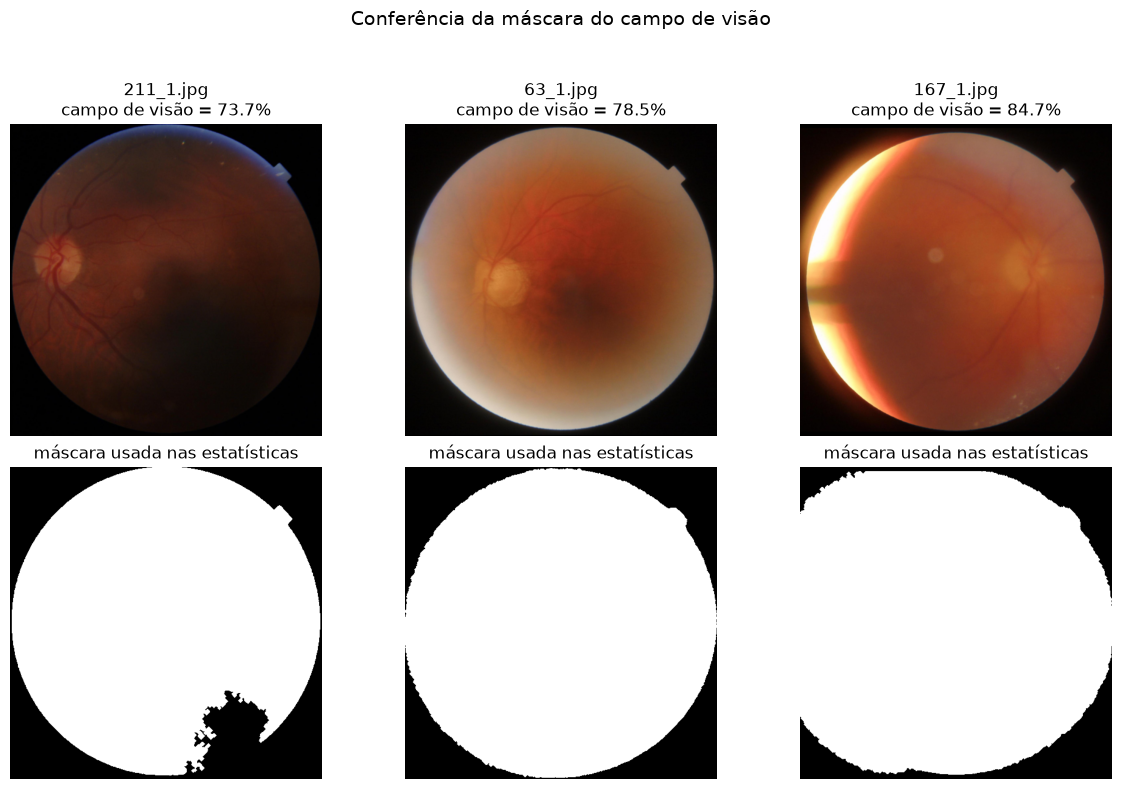

In [7]:
# Conferência visual da máscara: imagens com o menor, o mediano e o maior campo de visão
ordem = np.argsort(meta["fov_fracao"].to_numpy())
escolhidas = [ordem[0], ordem[len(ordem) // 2], ordem[-1]]

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for j, i in enumerate(escolhidas):
    rgb = carregar_reduzida(caminhos[i])
    axes[0, j].imshow(rgb)
    axes[0, j].set_title(f"{nomes[i]}\ncampo de visão = {meta['fov_fracao'].iloc[i]:.1%}")
    axes[1, j].imshow(mascara_fov(rgb), cmap="gray")
    axes[1, j].set_title("máscara usada nas estatísticas")
    for linha in (0, 1):
        axes[linha, j].axis("off")
fig.suptitle("Conferência da máscara do campo de visão", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

In [8]:
# V (brilho) é quase igual a R: confirmamos e descartamos as duas colunas de V
print(f"Correlação entre R_media e V_media: {np.corrcoef(X_trad_df['R_media'], X_trad_df['V_media'])[0, 1]:.4f}")
print(f"Correlação entre R_desvio e V_desvio: {np.corrcoef(X_trad_df['R_desvio'], X_trad_df['V_desvio'])[0, 1]:.4f}")
X_trad_df = X_trad_df.drop(columns=["V_media", "V_desvio"])

# Duas medidas fáceis de interpretar (brilho e nitidez) ficam na tabela meta, só para descrever os clusters depois
meta["brilho_R"] = X_trad_df["R_media"].to_numpy()
meta["nitidez"] = X_trad_df["gradiente_medio"].to_numpy()

np.save(OUT_DIR / "caracteristicas_tradicionais.npy", X_trad_df.to_numpy())
print(f"\nMatriz tradicional final: {X_trad_df.shape}")
display(X_trad_df.describe().T[["mean", "std", "min", "max"]].round(3).head(12))

Correlação entre R_media e V_media: 1.0000
Correlação entre R_desvio e V_desvio: 0.9997

Matriz tradicional final: (737, 37)


,mean,std,min,max
R_media,0.433,0.107,0.136,0.831
R_desvio,0.132,0.034,0.053,0.263
G_media,0.197,0.052,0.067,0.459
G_desvio,0.075,0.031,0.016,0.231
B_media,0.118,0.035,0.042,0.360
B_desvio,0.048,0.029,0.011,0.213
S_media,0.710,0.079,0.392,0.844
S_desvio,0.094,0.038,0.026,0.248
hist_R_0,0.038,0.048,0.003,0.587
hist_R_1,0.125,0.133,0.003,0.744


## 6. Normalização, PCA e abordagem híbrida

**Por que padronizar.** O K-Means usa distância euclidiana. As colunas têm escalas muito diferentes (histogramas entre 0 e 1, gradiente perto de 0,0x, embeddings entre cerca de -0,4 e 4,7). Sem padronizar, as colunas de maior escala decidiriam sozinhas. Cada coluna passa a ter média 0 e desvio 1.

**Por que PCA com 90% da variância.** Muitas colunas são redundantes (os histogramas de cor são correlacionados) e há 1024 colunas de embedding para 737 imagens. A PCA mantém as direções que concentram 90% da variação e descarta o resto, que é em boa parte ruído. Não usamos *whitening*, que daria o mesmo peso a componentes de ruído.

**Abordagem híbrida.** Padronizamos cada bloco separadamente e dividimos cada um pela raiz do seu número de colunas. Assim cada bloco contribui com a mesma variância total. Sem isso, o Deep Learning (cerca de 1000 colunas) dominaria as 37 tradicionais só pelo número de colunas.

**Sem rótulos.** Scaler e PCA usam somente as características. Eles são ajustados nas 737 imagens (na seção do roteador, ajustamos só no treino).

**Variáveis que não entram:** `Label`, `Quality Score`, `Patient`, formato e largura.

Colunas do embedding sem variação (removidas): 2 de 1024


,colunas originais,componentes PCA (90%),variância retida
Tradicional,37,11,0.902
Deep Learning,1022,137,0.901
Híbrida,1059,81,0.900


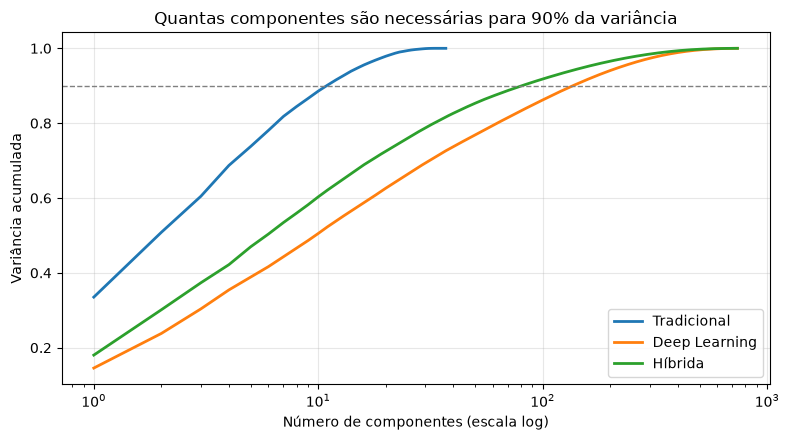

In [9]:
ABORDAGENS = ["Tradicional", "Deep Learning", "Híbrida"]

# Colunas do embedding sem nenhuma variação não servem para calcular distâncias
colunas_dl_validas = X_dl_bruto.std(axis=0) > 1e-6
print(f"Colunas do embedding sem variação (removidas): {int((~colunas_dl_validas).sum())} de {X_dl_bruto.shape[1]}")

X_dl = X_dl_bruto[:, colunas_dl_validas].astype(np.float64)
X_trad = X_trad_df.to_numpy(dtype=np.float64)


def matriz_padronizada(abordagem, idx=None, peso_trad=1.0, X_dl_usar=None):
    idx = np.arange(len(meta)) if idx is None else np.asarray(idx)
    Xd = X_dl if X_dl_usar is None else X_dl_usar
    blocos = []
    if abordagem in ("Tradicional", "Híbrida"):
        Zt = StandardScaler().fit_transform(X_trad[idx])
        blocos.append(Zt * (peso_trad / np.sqrt(Zt.shape[1])) if abordagem == "Híbrida" else Zt)
    if abordagem in ("Deep Learning", "Híbrida"):
        Zd = StandardScaler().fit_transform(Xd[idx])
        blocos.append(Zd / np.sqrt(Zd.shape[1]) if abordagem == "Híbrida" else Zd)
    return np.hstack(blocos)


def construir_P(abordagem, idx=None, peso_trad=1.0, X_dl_usar=None, variancia=0.90):
    # Padroniza, combina os blocos (híbrida) e aplica PCA. Devolve (matriz reduzida, objeto PCA)
    Z = matriz_padronizada(abordagem, idx, peso_trad, X_dl_usar)
    pca = PCA(n_components=variancia, svd_solver="full", random_state=SEED)
    return pca.fit_transform(Z), pca


P, PCAS = {}, {}
for ab in ABORDAGENS:
    P[ab], PCAS[ab] = construir_P(ab)

dimensoes = pd.DataFrame({
    "colunas originais": {"Tradicional": X_trad.shape[1], "Deep Learning": X_dl.shape[1],
                          "Híbrida": X_trad.shape[1] + X_dl.shape[1]},
    "componentes PCA (90%)": {ab: P[ab].shape[1] for ab in ABORDAGENS},
    "variância retida": {ab: PCAS[ab].explained_variance_ratio_.sum() for ab in ABORDAGENS},
})
display(dimensoes.round(3))

# Curvas de variância acumulada
fig, ax = plt.subplots(figsize=(8, 4.5))
for ab in ABORDAGENS:
    completa = PCA(svd_solver="full", random_state=SEED).fit(matriz_padronizada(ab))
    acumulada = np.cumsum(completa.explained_variance_ratio_)
    ax.plot(np.arange(1, len(acumulada) + 1), acumulada, label=ab, lw=2)
ax.axhline(0.90, color="gray", ls="--", lw=1)
ax.set_xscale("log")
ax.set_xlabel("Número de componentes (escala log)")
ax.set_ylabel("Variância acumulada")
ax.set_title("Quantas componentes são necessárias para 90% da variância")
ax.grid(True)
ax.legend()
plt.tight_layout()
plt.show()

> **Interpretação:** o número de componentes que guarda 90% da variância mostra como a informação está distribuída em cada abordagem.
>
> - **Tradicional: 37 → 11 componentes.** As 37 estatísticas são muito redundantes entre si (por exemplo, médias e histogramas de cor variam juntos com o brilho). Poucas componentes bastam.
> - **Deep Learning: 1.022 → 137 componentes.** A informação dos embeddings é espalhada. Nenhuma direção domina, e isso já antecipa agrupamentos pouco nítidos.
> - **Híbrida: 1.059 → 81 componentes.** Como cada bloco foi escalado para ter o mesmo peso total, as características tradicionais (37 colunas) passam a ter o mesmo peso que as 1.022 do embedding. Por isso a híbrida precisa de menos componentes que o Deep Learning.
>
> O PCA reduz ruído e deixa o K-Means mais estável, mas não escolhe o que é "importante clinicamente". Ele só mantém o que mais varia entre as imagens.

### O que as primeiras componentes representam?

A primeira componente é a direção em que as imagens mais variam. Se ela estiver muito ligada à qualidade ou ao brilho, o K-Means tende a separar as imagens por isso. Medimos a correlação de Spearman entre as 3 primeiras componentes e: o `Quality Score`, o brilho (média do canal R), a nitidez (gradiente médio) e o diagnóstico (`GON+` = 1).

Aqui `Quality Score`, brilho e nitidez servem só para **interpretar**. Eles não entraram no cálculo.

In [10]:
linhas = []
for ab in ABORDAGENS:
    for pc in range(3):
        linha = {"abordagem": ab, "componente": f"PC{pc + 1}",
                 "variância (%)": 100 * PCAS[ab].explained_variance_ratio_[pc]}
        for nome, coluna in [("Quality Score", "Quality Score"), ("brilho (R)", "brilho_R"),
                             ("nitidez", "nitidez"), ("GON+", "y_pos")]:
            linha[f"rho com {nome}"] = stats.spearmanr(P[ab][:, pc], meta[coluna]).statistic
        linhas.append(linha)

display(pd.DataFrame(linhas).set_index(["abordagem", "componente"]).round(2))

variância (%)  rho com Quality Score  \
abordagem     componente                                         
Tradicional   PC1                 33.52                   0.10   
              PC2                 17.32                  -0.36   
              PC3                  9.63                  -0.10   
Deep Learning PC1                 14.57                   0.57   
              PC2                  9.25                   0.33   
              PC3                  6.56                   0.34   
Híbrida       PC1                 18.03                   0.14   
              PC2                 12.12                   0.54   
              PC3                  7.21                   0.31   

                          rho com brilho (R)  rho com nitidez  rho com GON+  
abordagem     componente                                                     
Tradicional   PC1                       0.71             0.75          0.03  
              PC2                      -0.76            -0.35          0.16  
              PC3                      -0.17            -0.29         -0.08  
Deep Learning PC1                       0.33             0.33          0.40  
              PC2                       0.40             0.25         -0.60  
              PC3                      -0.10            -0.13         -0.15  
Híbrida       PC1                       0.72             0.77          0.08  
              PC2                       0.73             0.41         -0.12  
              PC3                      -0.10             0.09          0.52

> **Interpretação:** as primeiras componentes estão ligadas a **brilho e nitidez da foto**, não a diagnóstico.
>
> - **Tradicional:** a PC1 (33,5% da variância) acompanha brilho (ρ = 0,71) e nitidez (ρ = 0,75). A PC2 é quase o oposto do brilho (ρ = −0,76). Correlação com `GON+` é praticamente nula na PC1 (0,03).
> - **Deep Learning:** a PC1 está mais ligada ao `Quality Score` (ρ = 0,57) e a PC2 tem a correlação mais forte com o diagnóstico de todas (ρ = −0,60 com `GON+`). Ou seja, o embedding da rede carrega alguma informação que acompanha o diagnóstico, misturada com qualidade.
> - **Híbrida:** a PC1 e a PC2 seguem brilho e nitidez, como na tradicional. A PC3 aparece com ρ = 0,52 com `GON+`.
>
> Correlação não é causa. Aqui, `GON+` e `GON-` também diferem em origem das imagens (seção 10), então essa correlação pode vir de qualquer coisa que acompanhe o diagnóstico.

## 7. K-Means para vários valores de K

Rodamos o K-Means com K de 2 a 10 em cada uma das três matrizes (já padronizadas e reduzidas pela PCA).

- `n_init = 20`: o algoritmo roda 20 vezes com centroides iniciais diferentes e fica com o melhor resultado. Isso reduz o risco de cair num resultado ruim por azar.
- `random_state = 42`: o resultado é reproduzível.
- Os clusters são renumerados por **tamanho** (cluster 0 = o maior). Os números que o K-Means devolve são arbitrários, e assim a numeração fica estável entre execuções.

In [11]:
KS = list(range(2, 11))


def ordenar_por_tamanho(rotulos):
    # Renumera os clusters do maior (0) para o menor
    ordem = np.argsort(-np.bincount(rotulos), kind="stable")
    mapa = np.empty_like(ordem)
    mapa[ordem] = np.arange(len(ordem))
    return mapa[rotulos]


def varrer_kmeans(Z, ks=KS, n_init=20):
    linhas, rotulos = [], {}
    for k in ks:
        km = KMeans(n_clusters=k, n_init=n_init, random_state=SEED).fit(Z)
        l = ordenar_por_tamanho(km.labels_)
        rotulos[k] = l
        linhas.append({
            "K": k,
            "inércia": km.inertia_,
            "silhouette": silhouette_score(Z, l),
            "davies_bouldin": davies_bouldin_score(Z, l),
            "calinski_harabasz": calinski_harabasz_score(Z, l),
        })
    tabela = pd.DataFrame(linhas).set_index("K")
    tabela["queda_inércia_%"] = 100 * (1 - tabela["inércia"] / tabela["inércia"].shift(1))
    return tabela, rotulos


t0 = time.time()
METRICAS, ROTULOS = {}, {}
for ab in ABORDAGENS:
    METRICAS[ab], ROTULOS[ab] = varrer_kmeans(P[ab])
print(f"K-Means (K = {KS[0]} a {KS[-1]}) nas 3 abordagens: {time.time() - t0:.0f} s")

for ab in ABORDAGENS:
    print(f"\n=== {ab.upper()} (espaço com {P[ab].shape[1]} dimensões) ===")
    display(METRICAS[ab].round(3))

K-Means (K = 2 a 10) nas 3 abordagens: 3 s

=== TRADICIONAL (espaço com 11 dimensões) ===


,inércia,silhouette,davies_bouldin,calinski_harabasz,queda_inércia_%
K,,,,,
2,19323.946,0.312,1.602,200.216,NaN
3,16138.863,0.230,1.478,192.131,16.483
4,13798.632,0.203,1.359,191.045,14.501
5,12474.926,0.218,1.393,177.689,9.593
6,11486.981,0.210,1.383,166.741,7.919
7,10656.897,0.195,1.368,159.045,7.226
8,9867.431,0.196,1.291,155.362,7.408
9,9158.651,0.203,1.258,153.304,7.183
10,8558.439,0.198,1.206,151.292,6.553



=== DEEP LEARNING (espaço com 137 dimensões) ===


,inércia,silhouette,davies_bouldin,calinski_harabasz,queda_inércia_%
K,,,,,
2,599576.799,0.114,2.654,96.633,NaN
3,555304.211,0.100,2.560,81.357,7.384
4,529919.248,0.096,2.671,68.463,4.571
5,510491.275,0.077,2.700,60.194,3.666
6,497343.416,0.078,2.642,53.225,2.576
7,486044.823,0.072,2.686,48.152,2.272
8,476519.895,0.069,2.709,44.122,1.960
9,469421.038,0.063,2.838,40.513,1.490
10,462554.106,0.056,2.843,37.695,1.463



=== HÍBRIDA (espaço com 81 dimensões) ===


,inércia,silhouette,davies_bouldin,calinski_harabasz,queda_inércia_%
K,,,,,
2,1170.688,0.174,2.480,98.232,NaN
3,1070.775,0.113,2.260,87.870,8.535
4,994.779,0.091,2.252,81.635,7.097
5,942.332,0.093,2.100,74.731,5.272
6,893.573,0.090,2.087,70.939,5.174
7,863.874,0.084,2.117,65.247,3.324
8,838.715,0.084,2.127,60.649,2.912
9,814.808,0.088,2.033,57.220,2.850
10,799.923,0.076,2.189,53.240,1.827


## 8. Avaliação interna dos agrupamentos

| Métrica | O que mede | Melhor |
|---|---|---|
| Inércia (elbow) | soma das distâncias ao quadrado até o centroide | menor, mas sempre cai com K: procura-se o "cotovelo" |
| Silhouette | quanto cada imagem está mais perto do seu cluster do que do cluster vizinho (vai de -1 a 1) | maior |
| Davies-Bouldin | razão entre a dispersão dentro dos clusters e a distância entre eles | menor |
| Calinski-Harabasz | dispersão entre clusters dividida pela dispersão dentro deles | maior |

**Cuidados na leitura**
- **Os valores absolutos não são comparáveis entre as abordagens.** Os espaços têm 11, 137 e 81 dimensões. Em mais dimensões as distâncias tendem a ficar parecidas entre si e o silhouette cai. Comparamos o **formato das curvas**, não os valores.
- Silhouette e Calinski-Harabasz tendem a favorecer K pequeno, e Davies-Bouldin pode melhorar só porque K aumenta. Por isso nenhuma métrica sozinha escolhe o K.
- Pela regra empírica de Kaufman e Rousseeuw, silhouette abaixo de ~0,25 indica que não há estrutura de grupos substancial.
- Nenhuma métrica interna sabe o que é glaucoma: elas só medem geometria.

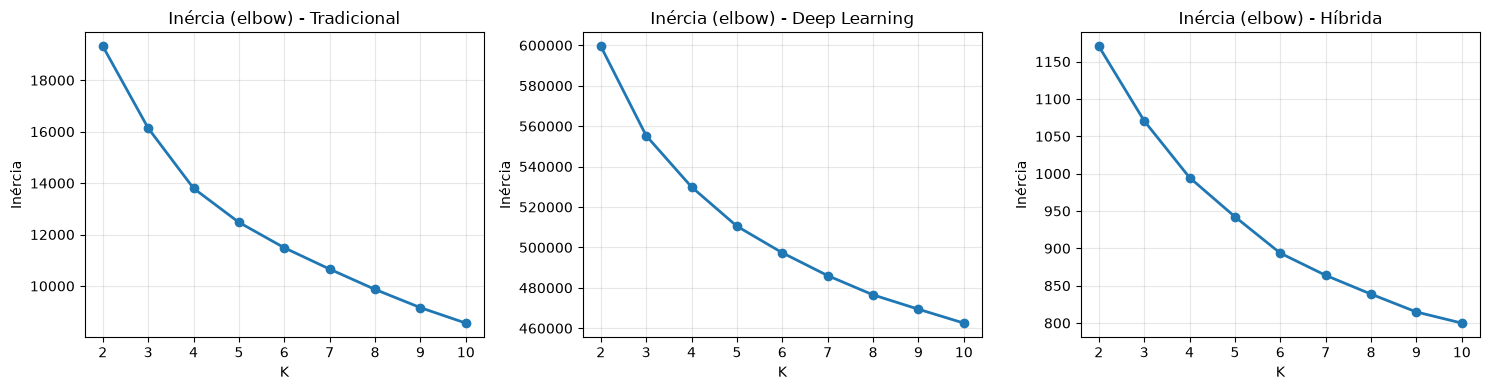

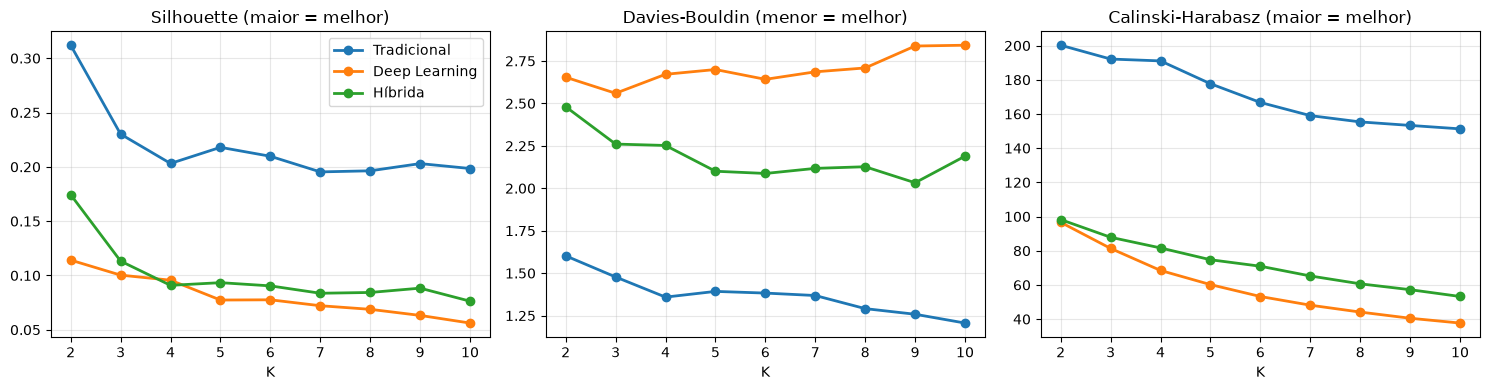

In [12]:
# Elbow: uma curva por abordagem (as escalas da inércia são diferentes)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, ab in zip(axes, ABORDAGENS):
    ax.plot(KS, METRICAS[ab]["inércia"], "o-", lw=2)
    ax.set_title(f"Inércia (elbow) - {ab}")
    ax.set_xlabel("K")
    ax.set_ylabel("Inércia")
    ax.set_xticks(KS)
    ax.grid(True)
plt.tight_layout()
plt.show()

# Silhouette, Davies-Bouldin e Calinski-Harabasz: as 3 abordagens juntas
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, coluna, titulo in zip(
    axes,
    ["silhouette", "davies_bouldin", "calinski_harabasz"],
    ["Silhouette (maior = melhor)", "Davies-Bouldin (menor = melhor)", "Calinski-Harabasz (maior = melhor)"],
):
    for ab in ABORDAGENS:
        ax.plot(KS, METRICAS[ab][coluna], "o-", lw=2, label=ab)
    ax.set_title(titulo)
    ax.set_xlabel("K")
    ax.set_xticks(KS)
    ax.grid(True)
axes[0].legend()
plt.tight_layout()
plt.show()

> **Interpretação:** nenhuma métrica aponta um K claramente melhor.
>
> - **Elbow:** a queda da inércia é gradual nas três abordagens (no Deep Learning cai de 7,4% para 1,5% sem nenhum "cotovelo" visível). Não há K onde a curva dobre de forma clara.
> - **Silhouette:** é baixa em tudo. A Tradicional tem 0,31 em K = 2 e fica em torno de 0,20 daí em diante. A Híbrida chega a 0,17 em K = 2 e cai para ≈ 0,09. O Deep Learning nunca passa de 0,11. Pela regra prática de Kaufman e Rousseeuw, valores abaixo de ≈ 0,25 indicam estrutura fraca: as imagens formam um contínuo, não grupos separados.
> - **Davies-Bouldin e Calinski-Harabasz:** a Tradicional parece "melhor" nas duas (DB ≈ 1,2–1,6; CH ≈ 150–200), mas isso **não** é comparável com as outras abordagens, porque o espaço tem 11 dimensões contra 137 e 81. Compare só as curvas dentro da mesma abordagem. O CH cai sempre com K, o que favorece K = 2 e não diz nada sobre grupos reais.
>
> Por isso o K de análise não sai das métricas internas. Escolhemos por estabilidade na próxima seção.

## 9. Estabilidade e escolha do K

As métricas internas não apontam um K claro, então olhamos também a **estabilidade**: um agrupamento confiável não deveria mudar muito se tirarmos parte dos dados.

**Como medimos:** sorteamos 80% dos **pacientes** (nunca separamos imagens do mesmo paciente), ajustamos o K-Means nessa parte e classificamos as 737 imagens com ele. Repetimos 10 vezes e calculamos o **ARI** médio entre os pares de resultados. O ARI vale 1 quando dois agrupamentos são iguais e perto de 0 quando não têm relação.

Nesta medida, scaler e PCA não são refeitos em cada sorteio, então ela mede só a estabilidade do K-Means.

**Diagnósticos externos, calculados depois do agrupamento e sem uso no ajuste:**
- **NMI com o diagnóstico** (`GON+`/`GON-`): quanto os clusters coincidem com o rótulo (0 = nada, 1 = idêntico). O valor de p vem de um teste de permutação **por paciente**: embaralhamos o rótulo entre pacientes (um paciente tem um único rótulo) e vemos quantas vezes o acaso iguala o NMI observado. Com 500 permutações, o menor p possível é cerca de 0,002.
- **η² da qualidade:** que fração da variação do `Quality Score` é explicada pelos clusters (0 = nada, 1 = tudo).
- **Coesão por paciente:** entre os pacientes com 2 ou mais imagens, que fração das imagens cai no cluster mais frequente do paciente. Comparamos com o que seria esperado ao acaso **mantendo a composição de diagnóstico de cada cluster** (embaralhamos os clusters dentro de `GON+` e dentro de `GON-`). Assim, uma coesão acima do acaso não vem só do diagnóstico.

**Regra para o K de análise (usa só estabilidade, sem rótulo):** o K entre 3 e 6 com a maior estabilidade. K = 2 fica de fora porque é uma divisão binária, fácil de ler como "doente x saudável" sem que seja. K acima de 6 deixa clusters pequenos para 737 imagens. Todos os K continuam nas tabelas.

In [13]:
Y = meta["y_pos"].to_numpy()
QUALIDADE = meta["Quality Score"].to_numpy()
N_PERM = 500


def estabilidade(Z, k, repeticoes=10, fracao=0.8):
    rng = np.random.default_rng(SEED)
    previsoes = []
    for r in range(repeticoes):
        sorteados = rng.choice(IDS_PAC, size=int(round(fracao * N_PAC)), replace=False)
        usar = np.isin(meta["Grupo"].to_numpy(), sorteados)
        km = KMeans(n_clusters=k, n_init=10, random_state=SEED + r).fit(Z[usar])
        previsoes.append(km.predict(Z))
    aris = [adjusted_rand_score(previsoes[i], previsoes[j])
            for i in range(repeticoes) for j in range(i + 1, repeticoes)]
    return float(np.mean(aris))


# --- Nulos para o teste do NMI: embaralha o rótulo ENTRE pacientes (cada paciente mantém um rótulo)
rotulo_por_paciente = meta.drop_duplicates("Grupo").set_index("Grupo")["y_pos"].reindex(IDS_PAC).to_numpy()
rng_nulo = np.random.default_rng(SEED)
NULOS_Y = np.stack([rng_nulo.permutation(rotulo_por_paciente)[IDX_PAC] for _ in range(N_PERM)])


def nmi_com_p(l):
    observado = normalized_mutual_info_score(Y, l)
    nulo = np.array([normalized_mutual_info_score(y_perm, l) for y_perm in NULOS_Y])
    return observado, (1 + np.sum(nulo >= observado)) / (N_PERM + 1)


def eta_quadrado(valores, l):
    v = np.asarray(valores, dtype=float)
    total = ((v - v.mean()) ** 2).sum()
    entre = sum((l == c).sum() * (v[l == c].mean() - v.mean()) ** 2 for c in np.unique(l))
    return entre / total


# --- Coesão por paciente (só pacientes com 2 ou mais imagens)
idx_multi = np.where(MULTI[IDX_PAC])[0]
_, pac_compacto = np.unique(IDX_PAC[idx_multi], return_inverse=True)
ESTRATOS = [np.where(Y == v)[0] for v in (0, 1)]


def coesao_paciente(l, k):
    contagem = np.zeros((pac_compacto.max() + 1, k))
    np.add.at(contagem, (pac_compacto, l[idx_multi]), 1)
    return contagem.max(axis=1).sum() / contagem.sum()


def coesao_nula(l, k, repeticoes=200):
    rng = np.random.default_rng(SEED)
    valores = []
    for _ in range(repeticoes):
        l_perm = l.copy()
        for idx in ESTRATOS:                       # embaralha os clusters dentro de cada diagnóstico
            l_perm[idx] = rng.permutation(l[idx])
        valores.append(coesao_paciente(l_perm, k))
    return np.array(valores)


t0 = time.time()
ESTAB = {ab: {k: estabilidade(P[ab], k) for k in KS} for ab in ABORDAGENS}
print(f"Estabilidade (10 reamostragens x {len(KS)} valores de K x 3 abordagens): {time.time() - t0:.0f} s")

linhas = []
for ab in ABORDAGENS:
    for k in KS:
        l = ROTULOS[ab][k]
        nmi_obs, p_nmi = nmi_com_p(l)
        linhas.append({
            "abordagem": ab, "K": k,
            "silhouette": METRICAS[ab].loc[k, "silhouette"],
            "davies_bouldin": METRICAS[ab].loc[k, "davies_bouldin"],
            "calinski_harabasz": METRICAS[ab].loc[k, "calinski_harabasz"],
            "estabilidade": ESTAB[ab][k],
            "menor_cluster": int(np.bincount(l).min()),
            "NMI_diagnóstico": nmi_obs, "p_NMI": p_nmi,
            "eta2_qualidade": eta_quadrado(QUALIDADE, l),
            "coesão_pacientes": coesao_paciente(l, k),
            "coesão_acaso": coesao_nula(l, k).mean(),
        })
DIAG = pd.DataFrame(linhas).set_index(["abordagem", "K"])
print(f"Diagnósticos externos calculados: {time.time() - t0:.0f} s no total")

for ab in ABORDAGENS:
    print(f"\n=== {ab.upper()} ===")
    display(DIAG.loc[ab].round(3))

Estabilidade (10 reamostragens x 9 valores de K x 3 abordagens): 11 s
Diagnósticos externos calculados: 27 s no total

=== TRADICIONAL ===


,silhouette,davies_bouldin,calinski_harabasz,estabilidade,menor_cluster,NMI_diagnóstico,p_NMI,eta2_qualidade,coesão_pacientes,coesão_acaso
K,,,,,,,,,,
2,0.312,1.602,200.216,0.828,198,0.001,0.365,0.008,0.826,0.778
3,0.230,1.478,192.131,0.718,27,0.001,0.541,0.039,0.788,0.693
4,0.203,1.359,191.045,0.753,12,0.008,0.070,0.053,0.713,0.600
5,0.218,1.393,177.689,0.662,13,0.010,0.054,0.084,0.689,0.568
6,0.210,1.383,166.741,0.627,5,0.015,0.010,0.086,0.655,0.545
7,0.195,1.368,159.045,0.524,10,0.007,0.224,0.138,0.605,0.497
8,0.196,1.291,155.362,0.496,3,0.009,0.120,0.108,0.599,0.512
9,0.203,1.258,153.304,0.493,3,0.010,0.114,0.146,0.584,0.484
10,0.198,1.206,151.292,0.504,3,0.012,0.084,0.140,0.556,0.458



=== DEEP LEARNING ===


,silhouette,davies_bouldin,calinski_harabasz,estabilidade,menor_cluster,NMI_diagnóstico,p_NMI,eta2_qualidade,coesão_pacientes,coesão_acaso
K,,,,,,,,,,
2,0.114,2.654,96.633,0.874,292,0.112,0.002,0.195,0.819,0.746
3,0.100,2.560,81.357,0.910,185,0.367,0.002,0.325,0.803,0.713
4,0.096,2.671,68.463,0.782,131,0.289,0.002,0.388,0.762,0.639
5,0.077,2.700,60.194,0.777,102,0.248,0.002,0.388,0.706,0.579
6,0.078,2.642,53.225,0.672,61,0.228,0.002,0.417,0.684,0.556
7,0.072,2.686,48.152,0.546,54,0.214,0.002,0.397,0.642,0.523
8,0.069,2.709,44.122,0.530,50,0.222,0.002,0.424,0.640,0.504
9,0.063,2.838,40.513,0.480,41,0.212,0.002,0.385,0.627,0.487
10,0.056,2.843,37.695,0.470,46,0.201,0.002,0.441,0.587,0.469



=== HÍBRIDA ===


,silhouette,davies_bouldin,calinski_harabasz,estabilidade,menor_cluster,NMI_diagnóstico,p_NMI,eta2_qualidade,coesão_pacientes,coesão_acaso
K,,,,,,,,,,
2,0.174,2.480,98.232,0.829,216,0.005,0.090,0.022,0.829,0.764
3,0.113,2.260,87.870,0.673,28,0.001,0.607,0.101,0.796,0.694
4,0.091,2.252,81.635,0.701,24,0.019,0.004,0.123,0.713,0.599
5,0.093,2.100,74.731,0.560,14,0.023,0.002,0.133,0.692,0.566
6,0.090,2.087,70.939,0.855,14,0.087,0.002,0.201,0.669,0.535
7,0.084,2.117,65.247,0.640,14,0.124,0.002,0.226,0.662,0.514
8,0.084,2.127,60.649,0.686,12,0.109,0.002,0.252,0.631,0.503
9,0.088,2.033,57.220,0.610,5,0.123,0.002,0.258,0.630,0.502
10,0.076,2.189,53.240,0.541,5,0.115,0.002,0.284,0.593,0.475


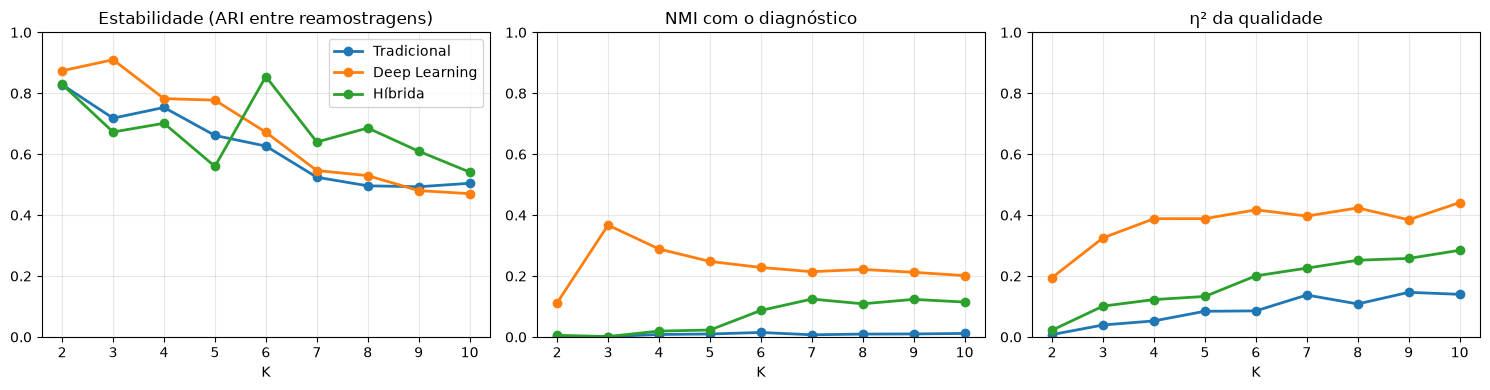

K de análise escolhido pela regra de estabilidade:
  Tradicional    K = 4 | estabilidade = 0.753 | tamanhos dos clusters: [304, 221, 200, 12]
  Deep Learning  K = 3 | estabilidade = 0.910 | tamanhos dos clusters: [296, 256, 185]
  Híbrida        K = 6 | estabilidade = 0.855 | tamanhos dos clusters: [207, 161, 159, 119, 77, 14]


In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, coluna, titulo in zip(
    axes,
    ["estabilidade", "NMI_diagnóstico", "eta2_qualidade"],
    ["Estabilidade (ARI entre reamostragens)", "NMI com o diagnóstico", "η² da qualidade"],
):
    for ab in ABORDAGENS:
        ax.plot(KS, DIAG.loc[ab][coluna], "o-", lw=2, label=ab)
    ax.set_title(titulo)
    ax.set_xlabel("K")
    ax.set_xticks(KS)
    ax.set_ylim(0, 1)
    ax.grid(True)
axes[0].legend()
plt.tight_layout()
plt.show()

# Regra: K entre 3 e 6 com a maior estabilidade (sem usar rótulo)
K_CANDIDATOS = [3, 4, 5, 6]
K_ESCOLHIDO = {ab: int(DIAG.loc[ab].loc[K_CANDIDATOS, "estabilidade"].idxmax()) for ab in ABORDAGENS}

print("K de análise escolhido pela regra de estabilidade:")
for ab in ABORDAGENS:
    k = K_ESCOLHIDO[ab]
    tamanhos = np.bincount(ROTULOS[ab][k]).tolist()
    print(f"  {ab:<14} K = {k} | estabilidade = {ESTAB[ab][k]:.3f} | tamanhos dos clusters: {tamanhos}")

In [15]:
# Conferência: no K = 2 da abordagem Tradicional os tamanhos dos clusters coincidem com os das classes?
l2 = ROTULOS["Tradicional"][2]
print("Tamanhos dos clusters (Tradicional, K = 2):", np.bincount(l2).tolist())
print("Tamanhos dos diagnósticos (GON+, GON-):    ", [int(Y.sum()), int((1 - Y).sum())])
display(pd.crosstab(l2, meta["Label"], rownames=["cluster"]))
print(f"NMI entre esses clusters e o diagnóstico: {normalized_mutual_info_score(Y, l2):.3f}")

Tamanhos dos clusters (Tradicional, K = 2): [539, 198]
Tamanhos dos diagnósticos (GON+, GON-):     [540, 197]


Label,GON+,GON-
cluster,,
0,389,150
1,151,47


NMI entre esses clusters e o diagnóstico: 0.001


> **Interpretação:**
>
> - **A estabilidade cai com K** nas três abordagens. Quanto mais clusters, mais a divisão depende de quais pacientes entraram na amostra.
> - **Tradicional (K = 4, estabilidade 0,75):** um dos 4 clusters tem só 12 imagens. K = 2 é mais estável (0,83), mas está fora da faixa 3–6 que definimos antes de olhar os resultados. O NMI com o diagnóstico é ≈ 0 em todos os K (no máximo 0,015), então a divisão tradicional não acompanha o diagnóstico.
> - **Deep Learning (K = 3, estabilidade 0,91):** é o agrupamento mais estável e o único cujo NMI com o diagnóstico é alto (0,37, p = 0,002 no teste de permutação por paciente). O η² do `Quality Score` também é o maior (0,33). Estabilidade alta aqui diz que a divisão é reprodutível, **não** que ela seja clinicamente significativa.
> - **Híbrida (K = 6, estabilidade 0,86):** a estabilidade oscila muito (0,67 em K = 3, 0,56 em K = 5 e 0,86 em K = 6). Esse comportamento irregular mostra que a híbrida está "entre" as duas outras e muda de lado conforme o K.
> - **Coesão por paciente:** em todos os casos, imagens do mesmo paciente caem juntas mais do que o acaso (ex.: Deep Learning K = 3: 0,80 contra 0,71 esperado). É esperado, porque fotos do mesmo paciente são parecidas em câmera, iluminação e dia.
> - **Coincidência a evitar:** no K = 2 da Tradicional, os tamanhos dos clusters (539 e 198) são quase iguais aos dos diagnósticos (540 `GON+` e 197 `GON-`), mas os grupos são diferentes (NMI = 0,001). É coincidência de tamanho.
>
> Escolhemos K = 4 (Tradicional), K = 3 (Deep Learning) e K = 6 (Híbrida) pela regra de estabilidade, que não usa nenhum rótulo.

## 10. O que os clusters representam?

Aqui vem a pergunta central da atividade: **os clusters refletem características úteis das imagens ou vieses de qualidade, origem e distribuição dos dados?** Eles **não** são diagnósticos nem estágios de glaucoma.

Para cada abordagem, no K escolhido, olhamos:
1. **Perfil de cada cluster:** tamanho, número de pacientes, composição `GON+`/`GON-`, qualidade, brilho, nitidez, largura da imagem e quantos arquivos PNG.
2. **Testes:** NMI com o diagnóstico (com teste de permutação por paciente), η² de qualidade, brilho, nitidez, largura e campo de visão, e coesão por paciente.
3. **Imagens:** as 5 mais típicas de cada cluster (mais perto do centro) e 5 sorteadas, sempre de pacientes diferentes. As sorteadas evitam enxergar só os casos mais "bonitos".

O brilho e a nitidez vêm das características tradicionais. Para a abordagem Tradicional elas também são entrada do K-Means, então ali a relação com elas é esperada. Para as outras duas, mostram o que o cluster captou sem ter sido pedido.

### Sinais de origem das imagens

O ID do paciente é uma cópia do diagnóstico (seção 2). Então procuramos sinais de origem que não dependam do ID: o formato real do arquivo, metadados internos e o tamanho da imagem.

In [16]:
import hashlib


def impressao_arquivo(caminho):
    with Image.open(caminho) as imagem:
        tabelas = getattr(imagem, "quantization", None)
        tabela = hashlib.md5(repr(sorted(tabelas.items())).encode()).hexdigest()[:8] if tabelas else "(não é JPEG)"
        return {"tabela_quantização_JPEG": tabela,
                "tags_EXIF": len(imagem.getexif()),
                "perfil_ICC": "icc_profile" in imagem.info}


origem = pd.DataFrame([impressao_arquivo(c) for c in caminhos])
origem["Label"] = meta["Label"].to_numpy()
origem["Formato"] = meta["Format"].to_numpy()

print("=== FORMATO E TABELA DE COMPRESSÃO x DIAGNÓSTICO ===")
display(pd.crosstab([origem["Formato"], origem["tabela_quantização_JPEG"]], origem["Label"]))
print(f"Imagens com tags EXIF: {int((origem['tags_EXIF'] > 0).sum())} | com perfil de cor ICC: {int(origem['perfil_ICC'].sum())}")

print("\n=== LARGURA DA IMAGEM (px) POR DIAGNÓSTICO ===")
display(meta.groupby("Label")["Width"].describe()[["count", "mean", "std", "min", "50%", "max"]].round(1))

=== FORMATO E TABELA DE COMPRESSÃO x DIAGNÓSTICO ===


,Label,GON+,GON-
Formato,tabela_quantização_JPEG,,
JPEG,0e368a84,540,186
PNG,(não é JPEG),0,11


Imagens com tags EXIF: 0 | com perfil de cor ICC: 0

=== LARGURA DA IMAGEM (px) POR DIAGNÓSTICO ===


,count,mean,std,min,50%,max
Label,,,,,,
GON+,540.0,1903.0,19.7,1873.0,1898.0,1960.0
GON-,197.0,1888.9,7.9,1876.0,1892.0,1910.0


> **Interpretação:** sinais técnicos que podem diferenciar `GON+` de `GON-` sem ter relação com a doença.
>
> - **Formato:** os 11 arquivos que são PNG com extensão `.jpg` são **todos `GON-`**. Entre os JPEG verdadeiros, todos usam a mesma tabela de quantização, então a compressão não separa os grupos.
> - **Metadados:** nenhuma imagem tem EXIF nem perfil ICC. Não temos como saber equipamento ou data por aí.
> - **Largura:** `GON-` são mais uniformes (média 1.889 px, desvio 7,9) e `GON+` variam mais (média 1.903 px, desvio 19,7). A diferença de média é pequena, mas a diferença de variação é grande. Isso é compatível com origens ou processamentos diferentes, mas os dados não permitem confirmar.
>
> Juntando com o achado da seção 2 (ID do paciente ≈ diagnóstico), há várias pistas de que `GON+` e `GON-` podem ter vindo de lotes diferentes. Qualquer cluster que separe diagnósticos pode estar separando lotes.

In [17]:
def perfil_clusters(l):
    d = meta.assign(cluster=l)
    g = d.groupby("cluster")
    perfil = pd.DataFrame({
        "n": g.size(),
        "pacientes": g["Grupo"].nunique(),
        "n_GON+": g["y_pos"].sum(),
        "n_GON-": g.size() - g["y_pos"].sum(),
        "%GON+": 100 * g["y_pos"].mean(),
        "qualidade": g["Quality Score"].mean(),
        "brilho_R": g["brilho_R"].mean(),
        "nitidez": g["nitidez"].mean(),
        "largura": g["Width"].mean(),
        "n_PNG": g["is_png"].sum(),
    })
    geral = pd.DataFrame({
        "n": [len(d)], "pacientes": [d["Grupo"].nunique()], "n_GON+": [d["y_pos"].sum()],
        "n_GON-": [len(d) - d["y_pos"].sum()], "%GON+": [100 * d["y_pos"].mean()],
        "qualidade": [d["Quality Score"].mean()], "brilho_R": [d["brilho_R"].mean()],
        "nitidez": [d["nitidez"].mean()], "largura": [d["Width"].mean()], "n_PNG": [d["is_png"].sum()],
    }, index=["todas"])
    return pd.concat([perfil, geral]).round({"%GON+": 1, "qualidade": 2, "brilho_R": 3, "nitidez": 4, "largura": 0})


def estatisticas_clusters(l, k):
    nmi_obs, p = nmi_com_p(l)
    print(f"NMI com o diagnóstico: {nmi_obs:.3f} (p de permutação por paciente = {p:.3f})")
    print("η² (fração da variação explicada pelos clusters):")
    for nome, coluna in [("Quality Score", "Quality Score"), ("brilho (R)", "brilho_R"), ("nitidez", "nitidez"),
                         ("largura da imagem", "Width"), ("campo de visão", "fov_fracao")]:
        print(f"   {nome:<20} {eta_quadrado(meta[coluna].to_numpy(), l):.3f}")
    nula = coesao_nula(l, k)
    print(f"Coesão por paciente: {coesao_paciente(l, k):.3f} | ao acaso, com a mesma composição de diagnóstico: "
          f"{nula.mean():.3f} (máximo em 200 sorteios: {nula.max():.3f})")


PACIENTES = meta["Grupo"].to_numpy()    # grupo de pacientes


def montagem(Z, l, k, n=5):
    rng = np.random.default_rng(SEED)
    fig, axes = plt.subplots(k, 2 * n, figsize=(2.0 * 2 * n, 2.2 * k))
    axes = np.atleast_2d(axes)
    for c in range(k):
        membros = np.where(l == c)[0]
        distancia = np.linalg.norm(Z[membros] - Z[membros].mean(axis=0), axis=1)
        tipicas = membros[np.argsort(distancia)]
        sorteadas = rng.permutation(membros)
        escolhidas = []
        for origem_lista, rotulo in ((tipicas, "típica"), (sorteadas, "sorteada")):
            usados, cont = set(), 0
            for i in origem_lista:
                if PACIENTES[i] in usados:
                    continue
                usados.add(PACIENTES[i])
                escolhidas.append((i, rotulo))
                cont += 1
                if cont == n:
                    break
        for j in range(2 * n):
            ax = axes[c, j]
            ax.axis("off")
            if j < len(escolhidas):
                i, rotulo = escolhidas[j]
                imagem = abrir_rgb(caminhos[i])
                imagem.thumbnail((256, 256))
                ax.imshow(imagem)
                ax.set_title(f"C{c} {rotulo}\n{meta['Label'].iloc[i]} | q={meta['Quality Score'].iloc[i]:.1f}", fontsize=8)
    plt.tight_layout()
    plt.show()


def analisar_abordagem(ab):
    k = K_ESCOLHIDO[ab]
    l = ROTULOS[ab][k]
    print(f"=== {ab.upper()} | K = {k} ===\n")
    display(perfil_clusters(l))
    print()
    estatisticas_clusters(l, k)
    montagem(P[ab], l, k)

### 10.1 Abordagem Tradicional

=== TRADICIONAL | K = 4 ===



,n,pacientes,n_GON+,n_GON-,%GON+,qualidade,brilho_R,nitidez,largura,n_PNG
0,304,173,204,100,67.1,6.02,0.447,0.0290,1895.0,8
1,221,133,171,50,77.4,5.60,0.322,0.0255,1892.0,3
2,200,120,155,45,77.5,6.09,0.526,0.0388,1911.0,0
3,12,12,10,2,83.3,5.11,0.570,0.0562,1937.0,0
todas,737,283,540,197,73.3,5.90,0.433,0.0310,1899.0,11



NMI com o diagnóstico: 0.008 (p de permutação por paciente = 0.070)
η² (fração da variação explicada pelos clusters):
   Quality Score        0.053
   brilho (R)           0.558
   nitidez              0.506
   largura da imagem    0.250
   campo de visão       0.138
Coesão por paciente: 0.713 | ao acaso, com a mesma composição de diagnóstico: 0.600 (máximo em 200 sorteios: 0.634)


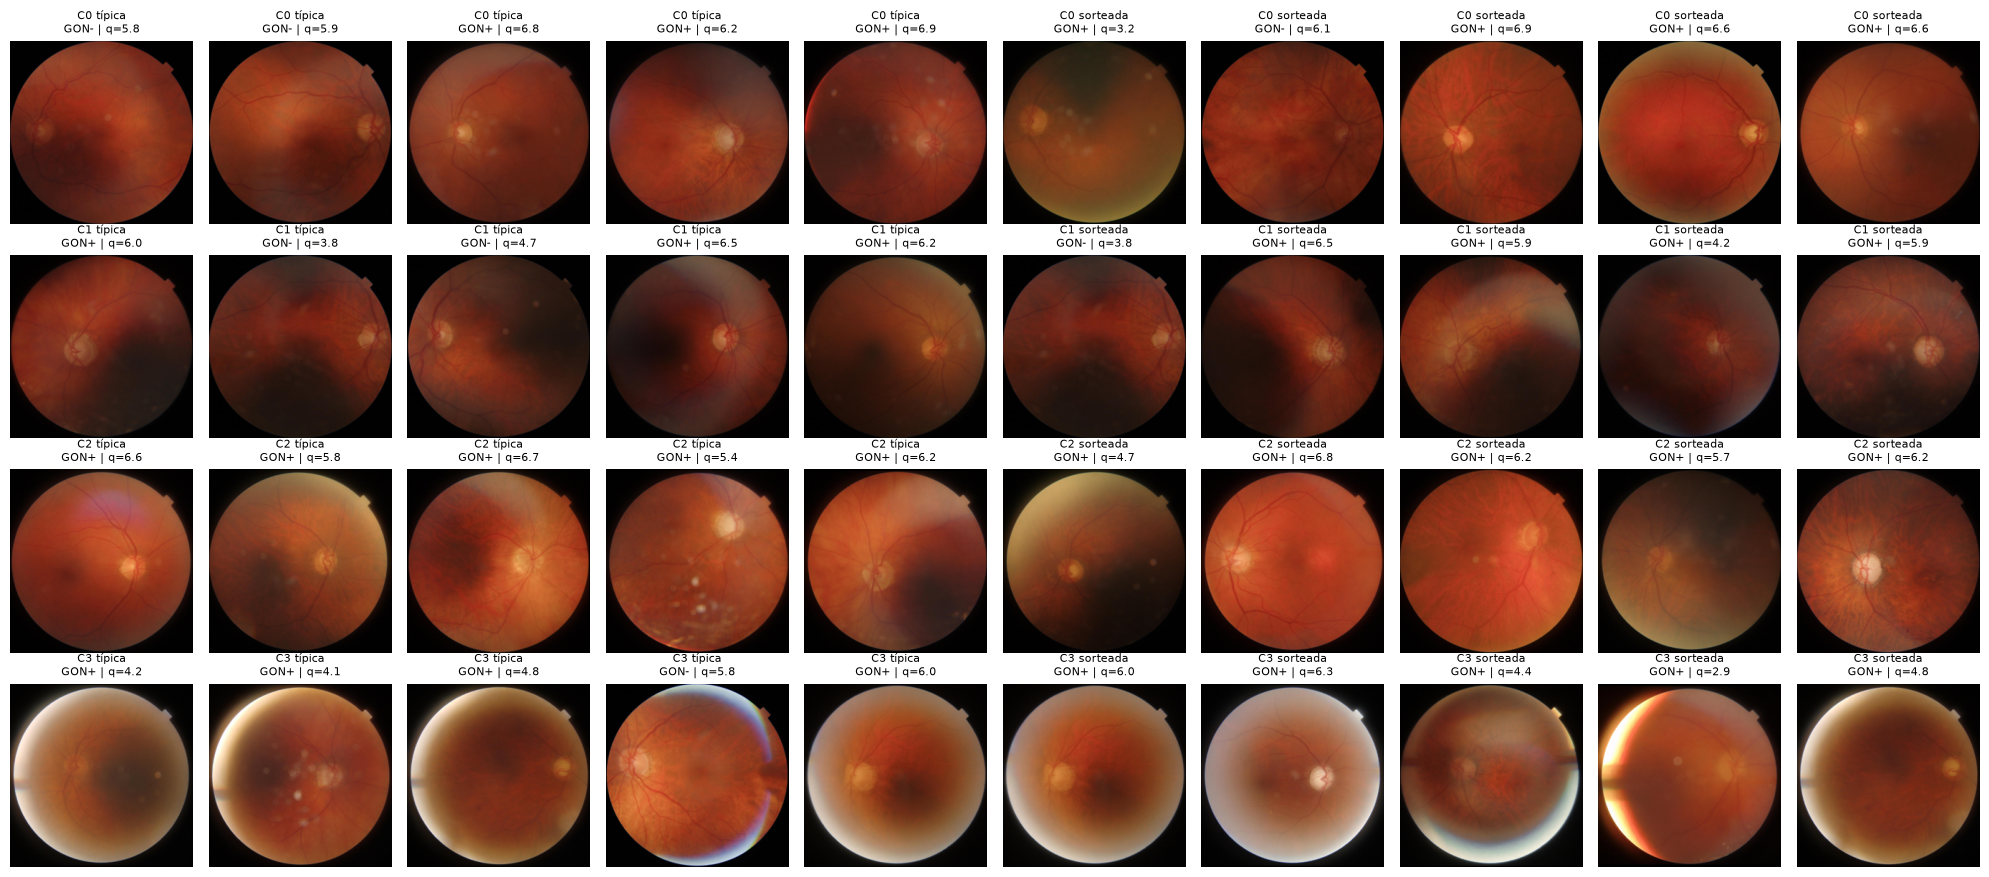

In [18]:
analisar_abordagem("Tradicional")

> **Interpretação (Tradicional, K = 4):** os clusters separam **brilho e nitidez**, e quase nada além disso.
>
> - **C0 (304), C1 (221), C2 (200):** vão do mais escuro (brilho R = 0,32 no C1) ao mais claro (0,53 no C2). A nitidez acompanha. Nos três, `GON+` fica entre 67% e 78%, perto dos 73% gerais.
> - **C3 (12 imagens):** grupo minúsculo, mais claro e mais nítido (brilho 0,57; nitidez 0,056). É um conjunto de poucas imagens extremas, não um grupo "natural".
> - **Diagnóstico:** NMI = 0,008 (p = 0,070). Não há relação com `GON+/GON-`.
> - **Qualidade:** η² do `Quality Score` = 0,053, contra 0,56 do brilho e 0,51 da nitidez. Os clusters seguem o que as características medem (brilho, nitidez), não a nota de qualidade.
> - **Largura:** η² = 0,25. Imagens mais largas caem nos clusters mais claros (ver seção 10.4).
> - **Montagem:** as imagens típicas confirmam: C1 é escuro, C2 e C3 são claros, e C3 tem iluminação estourada na borda.
> - **Coesão por paciente** (0,71) fica acima do acaso (0,60; máximo em 200 sorteios: 0,63).

### 10.2 Abordagem Deep Learning

=== DEEP LEARNING | K = 3 ===



,n,pacientes,n_GON+,n_GON-,%GON+,qualidade,brilho_R,nitidez,largura,n_PNG
0,296,156,272,24,91.9,5.21,0.387,0.0285,1902.0,0
1,256,118,244,12,95.3,6.48,0.471,0.0333,1902.0,0
2,185,109,24,161,13.0,6.19,0.456,0.0319,1891.0,11
todas,737,283,540,197,73.3,5.90,0.433,0.0310,1899.0,11



NMI com o diagnóstico: 0.367 (p de permutação por paciente = 0.002)
η² (fração da variação explicada pelos clusters):
   Quality Score        0.325
   brilho (R)           0.129
   nitidez              0.063
   largura da imagem    0.073
   campo de visão       0.093
Coesão por paciente: 0.803 | ao acaso, com a mesma composição de diagnóstico: 0.713 (máximo em 200 sorteios: 0.750)


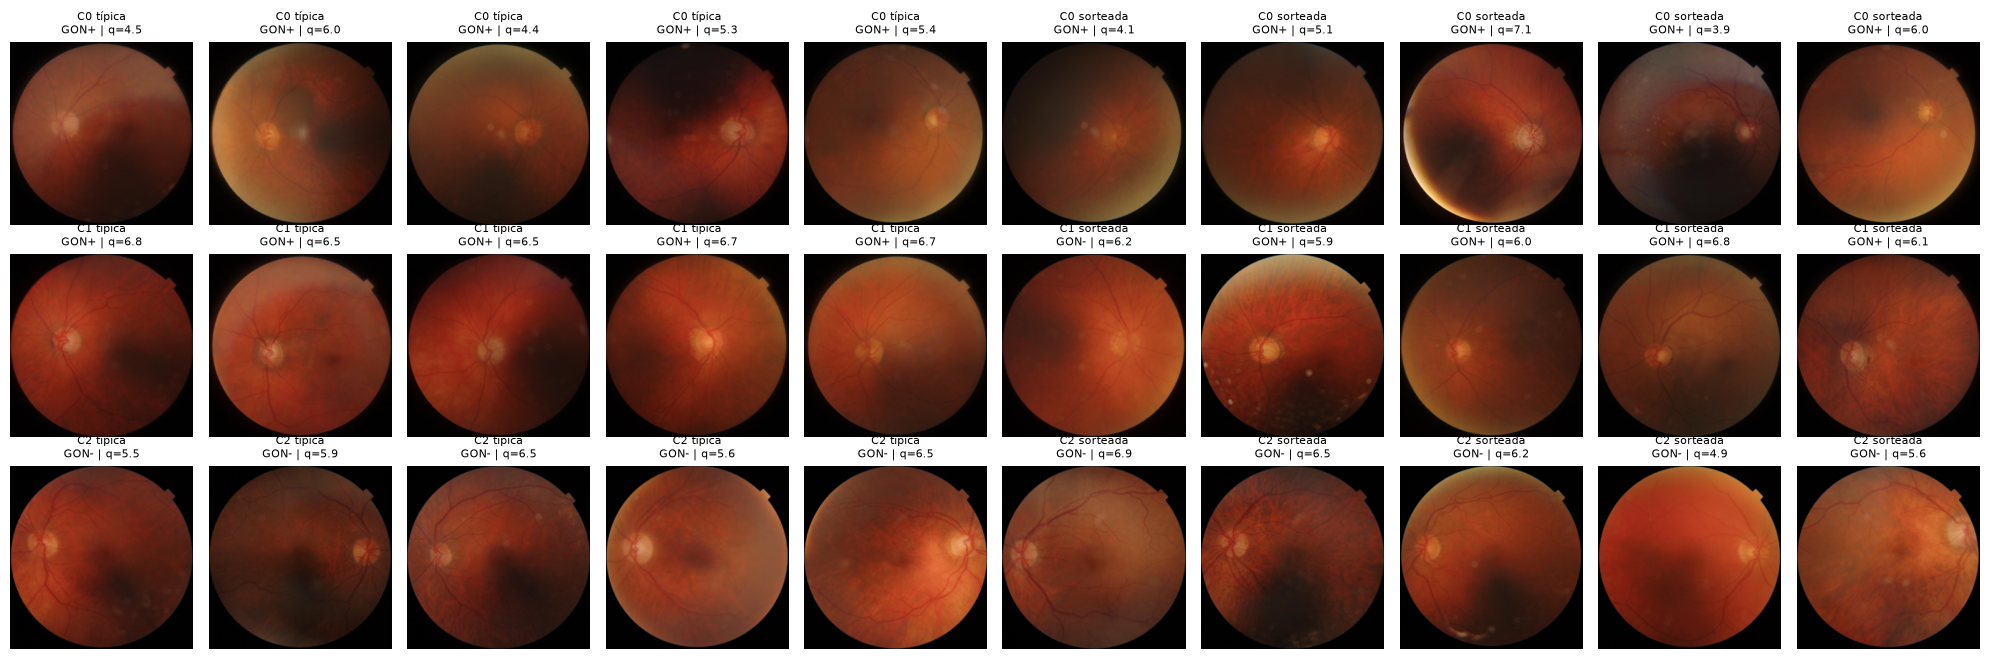

In [19]:
analisar_abordagem("Deep Learning")

> **Interpretação (Deep Learning, K = 3):** o embedding separa dois grupos de `GON+` e um grupo com quase todos os `GON-`.
>
> - **C0 (296):** 92% `GON+`, qualidade mais baixa (5,21), mais escuro (brilho 0,387). As imagens típicas são mais escuras e menos nítidas.
> - **C1 (256):** 95% `GON+`, qualidade mais alta (6,48), imagens mais claras e bem focadas.
> - **C2 (185):** só 13% `GON+`: contém 161 dos 197 `GON-` **e todos os 11 PNG**. Qualidade 6,19 (parecida com C1).
> - **NMI com o diagnóstico = 0,37** (p = 0,002). Pelo teste de permutação por paciente, isso é muito acima do acaso.
>
> **Como ler isso, com cuidado:**
> - O C0 contra o C1 é uma divisão ligada a **qualidade da imagem** (η² = 0,33; diferença de 1,3 ponto de nota), dentro de `GON+`. Isso é um viés de qualidade, não um subtipo.
> - O C2 reúne os `GON-`. Mas, como `GON-` também têm outra origem (ID, formato PNG, largura mais uniforme; seção 10), a rede pode estar reconhecendo **a origem das imagens**, não sinais da doença. Não dá para separar as duas explicações com estes dados.
> - Nenhum cluster deve ser lido como "glaucoma" ou "saudável".

### 10.3 Abordagem Híbrida

=== HÍBRIDA | K = 6 ===



,n,pacientes,n_GON+,n_GON-,%GON+,qualidade,brilho_R,nitidez,largura,n_PNG
0,207,134,94,113,45.4,5.80,0.439,0.0287,1893.0,9
1,161,102,123,38,76.4,5.42,0.305,0.0245,1891.0,2
2,159,82,152,7,95.6,6.56,0.458,0.0308,1897.0,0
3,119,85,103,16,86.6,5.55,0.431,0.0324,1911.0,0
4,77,48,56,21,72.7,6.43,0.617,0.0449,1914.0,0
5,14,14,12,2,85.7,5.31,0.551,0.0553,1934.0,0
todas,737,283,540,197,73.3,5.90,0.433,0.0310,1899.0,11



NMI com o diagnóstico: 0.087 (p de permutação por paciente = 0.002)
η² (fração da variação explicada pelos clusters):
   Quality Score        0.201
   brilho (R)           0.650
   nitidez              0.568
   largura da imagem    0.276
   campo de visão       0.283
Coesão por paciente: 0.669 | ao acaso, com a mesma composição de diagnóstico: 0.535 (máximo em 200 sorteios: 0.576)


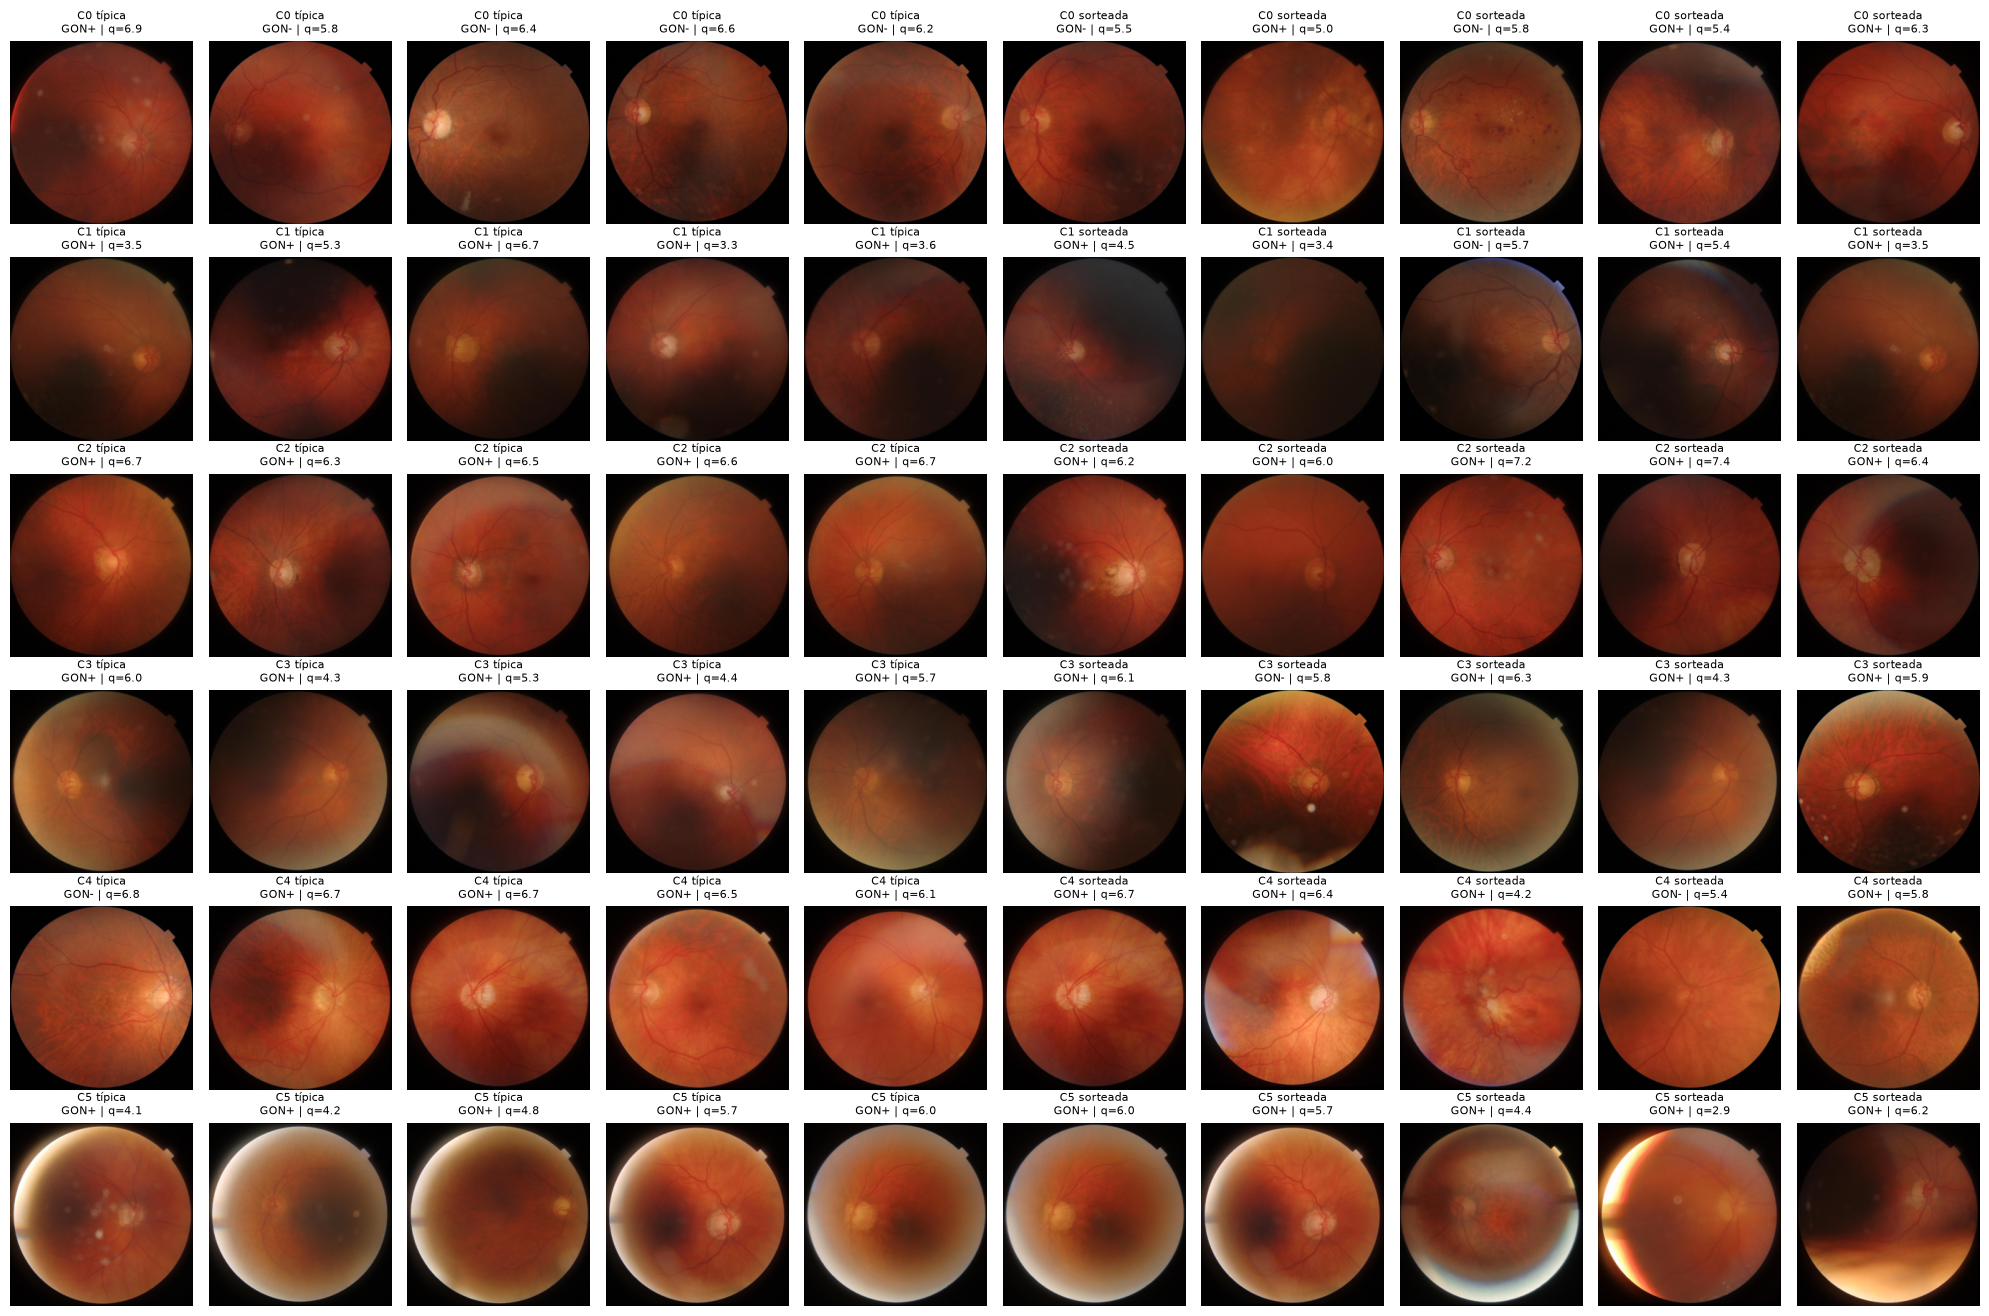

In [20]:
analisar_abordagem("Híbrida")

> **Interpretação (Híbrida, K = 6):** mistura os dois tipos de separação.
>
> - **Clusters ligados a brilho e nitidez (como na Tradicional):** C1 é o mais escuro (brilho 0,305), C4 é o mais claro (0,617) e C5 (14 imagens) é muito nítido (0,055).
> - **Clusters ligados ao diagnóstico (como no Deep Learning):** C0 tem 45% `GON+` e contém 113 dos 197 `GON-` e 9 dos 11 PNG. C2 tem 96% `GON+` e a maior qualidade (6,56).
> - **NMI = 0,087** (p = 0,002): relação com o diagnóstico fraca, mas acima do acaso.
> - **Brilho (η² = 0,65) e nitidez (0,57)** explicam mais que a qualidade (0,20). O campo de visão também pesa (0,28), e a largura (0,28).
>
> Dois clusters (C5 com 14 e C4 com 77) são pequenos e dependem do extremo da distribuição. A híbrida não "soma o melhor" das duas: ela mostra os dois efeitos ao mesmo tempo.

### 10.4 A largura da imagem explica os clusters?

Os `GON-` têm larguras num intervalo estreito e os `GON+` num intervalo mais largo (tabela da seção 10). Isso pode indicar fontes ou processamentos diferentes. Para saber se os clusters seguem a largura, olhamos **só os `GON+`** (que têm larguras variadas) e vemos como cada faixa de largura se distribui pelos clusters. Se os clusters seguissem a largura, cada faixa cairia em clusters diferentes.

In [21]:
faixas_largura = pd.cut(meta["Width"], bins=[0, 1890, 1910, 2000], labels=["até 1890 px", "1891 a 1910 px", "acima de 1910 px"])
somente_pos = (meta["y_pos"] == 1).to_numpy()

for ab in ABORDAGENS:
    k = K_ESCOLHIDO[ab]
    tabela = pd.crosstab(faixas_largura[somente_pos].to_numpy(), ROTULOS[ab][k][somente_pos],
                         rownames=["largura (só GON+)"], colnames=[f"cluster ({ab}, K = {k})"])
    print(f"=== {ab.upper()} ===")
    display(tabela)
    print(f"NMI entre faixa de largura e cluster (só GON+): "
          f"{normalized_mutual_info_score(faixas_largura[somente_pos].astype(str), ROTULOS[ab][k][somente_pos]):.3f}\n")

=== TRADICIONAL ===


"cluster (Tradicional, K = 4)",0,1,2,3
largura (só GON+),,,,
1891 a 1910 px,84,78,34,0
acima de 1910 px,43,25,103,10
até 1890 px,77,68,18,0


NMI entre faixa de largura e cluster (só GON+): 0.116

=== DEEP LEARNING ===


"cluster (Deep Learning, K = 3)",0,1,2
largura (só GON+),,,
1891 a 1910 px,113,76,7
acima de 1910 px,90,84,7
até 1890 px,69,84,10


NMI entre faixa de largura e cluster (só GON+): 0.009

=== HÍBRIDA ===


"cluster (Híbrida, K = 6)",0,1,2,3,4,5
largura (só GON+),,,,,,
1891 a 1910 px,45,56,51,36,7,1
acima de 1910 px,14,14,41,60,41,11
até 1890 px,35,53,60,7,8,0


NMI entre faixa de largura e cluster (só GON+): 0.105



> **Interpretação:** só entre `GON+`, a largura **não** explica o cluster do Deep Learning (NMI = 0,009; as faixas de largura se distribuem de forma parecida nos 3 clusters). Isso mostra que a separação do Deep Learning entre `GON+` e `GON-` **não** vem apenas da diferença de largura.
>
> Nas abordagens Tradicional (NMI = 0,116) e Híbrida (0,105), a largura tem alguma relação: imagens com mais de 1.910 px ficam principalmente nos clusters claros (no C2 da Tradicional, 103 das 155 imagens `GON+`). Provavelmente, imagens mais largas e mais claras vêm do mesmo tipo de equipamento ou de ajuste de captura. Isso reforça que os clusters tradicionais descrevem **condições de captura**.
>
> Isso afasta a explicação mais simples (a largura), mas não elimina outras diferenças de origem que não medimos.

## 11. Visualização com t-SNE

O t-SNE desenha cada imagem como um ponto em 2D, mantendo vizinhos próximos. Usamos o espaço reduzido pela PCA de cada abordagem, `perplexity = 30` e `random_state = 42`.

**Como ler:** o t-SNE preserva a vizinhança local, mas **não** a distância entre grupos nem o tamanho deles. Ele serve para ver, não para medir. UMAP seria a alternativa, mas não está instalado no projeto, e o t-SNE já cumpre o que a atividade pede.

Cada linha é uma abordagem e cada coluna pinta os pontos de um jeito: pelo **cluster** (K escolhido), pelo **diagnóstico** e pelo **Quality Score**.

t-SNE das 3 abordagens: 3 s


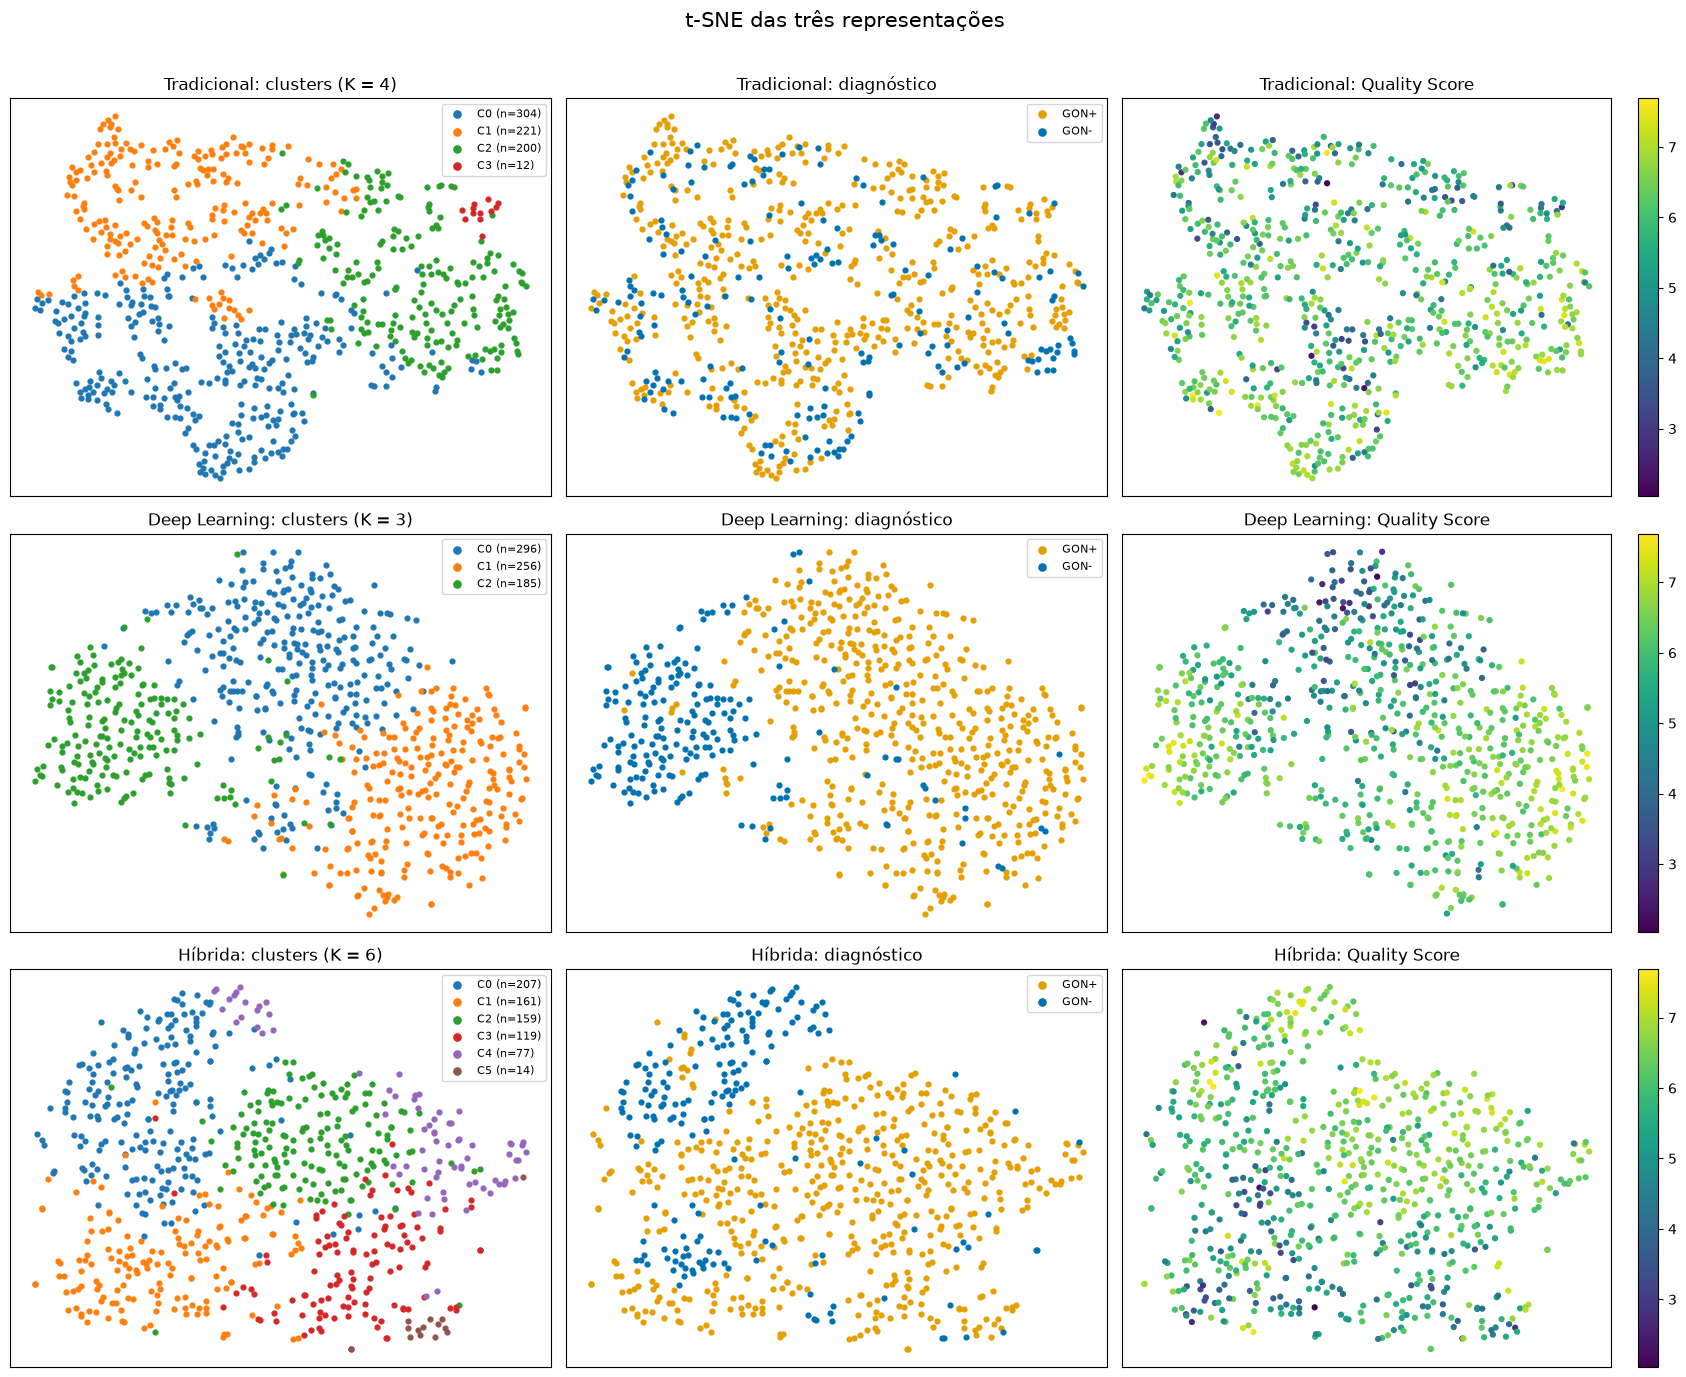

In [22]:
t0 = time.time()
TSNE_COORD = {
    ab: TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto", random_state=SEED).fit_transform(P[ab])
    for ab in ABORDAGENS
}
print(f"t-SNE das 3 abordagens: {time.time() - t0:.0f} s")

COR_DIAG = {"GON+": "#E69F00", "GON-": "#0072B2"}
cores_cluster = plt.get_cmap("tab10")

fig, axes = plt.subplots(3, 3, figsize=(17, 14))
for linha, ab in enumerate(ABORDAGENS):
    xy = TSNE_COORD[ab]
    k = K_ESCOLHIDO[ab]
    l = ROTULOS[ab][k]

    ax = axes[linha, 0]
    for c in range(k):
        ax.scatter(xy[l == c, 0], xy[l == c, 1], s=12, color=cores_cluster(c), label=f"C{c} (n={int((l == c).sum())})")
    ax.set_title(f"{ab}: clusters (K = {k})")
    ax.legend(fontsize=8, markerscale=1.5)

    ax = axes[linha, 1]
    for rotulo, cor in COR_DIAG.items():
        mascara = (meta["Label"] == rotulo).to_numpy()
        ax.scatter(xy[mascara, 0], xy[mascara, 1], s=12, color=cor, label=rotulo)
    ax.set_title(f"{ab}: diagnóstico")
    ax.legend(fontsize=8, markerscale=1.5)

    ax = axes[linha, 2]
    pontos = ax.scatter(xy[:, 0], xy[:, 1], s=12, c=meta["Quality Score"], cmap="viridis")
    ax.set_title(f"{ab}: Quality Score")
    fig.colorbar(pontos, ax=ax, fraction=0.046)

    for coluna in range(3):
        axes[linha, coluna].set_xticks([])
        axes[linha, coluna].set_yticks([])
fig.suptitle("t-SNE das três representações", fontsize=15)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

> **Interpretação:** o t-SNE é só um mapa para olhar. Distâncias entre grupos distantes não têm significado, e as formas dependem de parâmetros.
>
> - **Tradicional:** os clusters ocupam regiões que acompanham o brilho (do escuro ao claro). Colorindo por diagnóstico, `GON+` e `GON-` aparecem misturados.
> - **Deep Learning:** os `GON-` formam uma região compacta própria, coerente com o C2. Os `GON+` ocupam o resto, divididos em duas zonas ligadas à qualidade.
> - **Híbrida:** os clusters ficam misturados e sem fronteira nítida, o que combina com as silhouettes baixas (≈ 0,09).
>
> Em nenhum dos três mapas existem "ilhas" bem separadas. É a mesma conclusão das métricas internas: as imagens formam um contínuo.

## 12. Comparação entre as três abordagens

Comparamos de três formas:
1. **No K escolhido de cada abordagem** (tabela principal).
2. **Num K comum (K = 3)**, para comparar no mesmo número de clusters.
3. **Quanto os agrupamentos concordam entre si** (ARI), e como o peso dado às características tradicionais move a abordagem híbrida.

Lembrete: não comparamos o valor absoluto de silhouette, Davies-Bouldin e Calinski-Harabasz entre abordagens (seção 8).

In [23]:
colunas_resumo = ["silhouette", "davies_bouldin", "estabilidade", "menor_cluster", "NMI_diagnóstico", "p_NMI",
                  "eta2_qualidade", "coesão_pacientes", "coesão_acaso"]

print("=== NO K ESCOLHIDO DE CADA ABORDAGEM ===")
resumo = pd.DataFrame([{"abordagem": ab, "K": K_ESCOLHIDO[ab], **DIAG.loc[(ab, K_ESCOLHIDO[ab]), colunas_resumo].to_dict()}
                       for ab in ABORDAGENS]).set_index("abordagem")
display(resumo.round(3))

K_COMUM = 3
print(f"\n=== NO MESMO K PARA TODAS (K = {K_COMUM}) ===")
display(DIAG.xs(K_COMUM, level="K")[colunas_resumo].round(3))

print("\n=== CONCORDÂNCIA ENTRE AS ABORDAGENS (ARI), cada uma no seu K escolhido ===")
ari_escolhido = pd.DataFrame(
    [[adjusted_rand_score(ROTULOS[a][K_ESCOLHIDO[a]], ROTULOS[b][K_ESCOLHIDO[b]]) for b in ABORDAGENS] for a in ABORDAGENS],
    index=ABORDAGENS, columns=ABORDAGENS)
display(ari_escolhido.round(3))

print(f"\n=== CONCORDÂNCIA ENTRE AS ABORDAGENS (ARI), todas em K = {K_COMUM} ===")
ari_comum = pd.DataFrame(
    [[adjusted_rand_score(ROTULOS[a][K_COMUM], ROTULOS[b][K_COMUM]) for b in ABORDAGENS] for a in ABORDAGENS],
    index=ABORDAGENS, columns=ABORDAGENS)
display(ari_comum.round(3))

=== NO K ESCOLHIDO DE CADA ABORDAGEM ===


,K,silhouette,davies_bouldin,estabilidade,menor_cluster,NMI_diagnóstico,p_NMI,eta2_qualidade,coesão_pacientes,coesão_acaso
abordagem,,,,,,,,,,
Tradicional,4,0.203,1.359,0.753,12.0,0.008,0.070,0.053,0.713,0.600
Deep Learning,3,0.100,2.560,0.910,185.0,0.367,0.002,0.325,0.803,0.713
Híbrida,6,0.090,2.087,0.855,14.0,0.087,0.002,0.201,0.669,0.535



=== NO MESMO K PARA TODAS (K = 3) ===


,silhouette,davies_bouldin,estabilidade,menor_cluster,NMI_diagnóstico,p_NMI,eta2_qualidade,coesão_pacientes,coesão_acaso
abordagem,,,,,,,,,
Tradicional,0.230,1.478,0.718,27,0.001,0.541,0.039,0.788,0.693
Deep Learning,0.100,2.560,0.910,185,0.367,0.002,0.325,0.803,0.713
Híbrida,0.113,2.260,0.673,28,0.001,0.607,0.101,0.796,0.694



=== CONCORDÂNCIA ENTRE AS ABORDAGENS (ARI), cada uma no seu K escolhido ===


,Tradicional,Deep Learning,Híbrida
Tradicional,1.000,0.027,0.436
Deep Learning,0.027,1.000,0.242
Híbrida,0.436,0.242,1.000



=== CONCORDÂNCIA ENTRE AS ABORDAGENS (ARI), todas em K = 3 ===


,Tradicional,Deep Learning,Híbrida
Tradicional,1.000,0.014,0.605
Deep Learning,0.014,1.000,0.085
Híbrida,0.605,0.085,1.000


### Peso das características tradicionais na abordagem híbrida

A abordagem híbrida depende de um peso: quanto o bloco tradicional conta em relação ao Deep Learning. Com peso 1 (o que usamos), cada bloco tem a mesma variância total. Testamos outros pesos em K = 3 e vemos se a híbrida se parece mais com a Tradicional ou com o Deep Learning (ARI) e como ela se relaciona com o diagnóstico e a qualidade.

In [24]:
ref_trad = ROTULOS["Tradicional"][K_COMUM]
ref_dl = ROTULOS["Deep Learning"][K_COMUM]

linhas = []
for peso in [0.25, 0.5, 1.0, 2.0, 4.0]:
    Pw, pca_w = construir_P("Híbrida", peso_trad=peso)
    l = ordenar_por_tamanho(KMeans(K_COMUM, n_init=20, random_state=SEED).fit_predict(Pw))
    if peso == 1.0:
        reproduz = adjusted_rand_score(l, ROTULOS["Híbrida"][K_COMUM]) == 1.0
    linhas.append({
        "peso do bloco tradicional": peso,
        "componentes PCA": Pw.shape[1],
        "ARI com Tradicional": adjusted_rand_score(l, ref_trad),
        "ARI com Deep Learning": adjusted_rand_score(l, ref_dl),
        "NMI com diagnóstico": normalized_mutual_info_score(Y, l),
        "η² qualidade": eta_quadrado(QUALIDADE, l),
        "tamanhos": np.bincount(l).tolist(),
    })

print(f"Peso 1.0 reproduz a abordagem híbrida da seção 6: {reproduz}")
display(pd.DataFrame(linhas).set_index("peso do bloco tradicional").round(3))

Peso 1.0 reproduz a abordagem híbrida da seção 6: True


,componentes PCA,ARI com Tradicional,ARI com Deep Learning,NMI com diagnóstico,η² qualidade,tamanhos
peso do bloco tradicional,,,,,,
0.25,138,0.014,0.889,0.343,0.348,"[275, 272, 190]"
0.50,125,0.018,0.741,0.255,0.328,"[269, 256, 212]"
1.00,81,0.605,0.085,0.001,0.101,"[413, 296, 28]"
2.00,30,0.938,0.020,0.001,0.044,"[406, 304, 27]"
4.00,15,0.995,0.015,0.001,0.039,"[407, 303, 27]"


> **Interpretação:**
>
> - **Tradicional x Deep Learning são abordagens que concordam quase nada** (ARI = 0,03 nos K escolhidos; 0,01 no K = 3). Elas agrupam as imagens por critérios diferentes: brilho/nitidez de um lado, padrão aprendido pela rede do outro.
> - **A híbrida fica entre as duas, mas depende do peso.** Com peso 1 (como na seção 6) ela se parece com a Tradicional (ARI = 0,61 no K = 3; NMI com o diagnóstico = 0,001). Com peso 0,25, ela vira praticamente o Deep Learning (ARI = 0,89; NMI = 0,34). A "híbrida" é, na prática, quem tem mais peso no bloco. Por isso o resultado dela precisa ser lido junto com o peso escolhido.
> - **Quem separa melhor?** No sentido de silhouette, a Tradicional (0,20 contra 0,10 e 0,09), mas ela mede em outro espaço (11 dimensões) e separa brilho, não doença. O Deep Learning é o mais estável (0,91) e tem a maior relação com o diagnóstico (NMI = 0,37), mas essa relação pode ser de origem das imagens, como discutido.
> - **Não existe um "vencedor" objetivo.** Cada abordagem responde a uma pergunta diferente. A escolha depende do que se quer investigar.

## 13. Testes de sensibilidade (experimentação adicional)

Uma conclusão só é confiável se não depender de detalhes da análise. Testamos duas coisas:

**13.1 Dependência de imagens específicas.** Refazemos todo o pipeline (padronização, PCA e K-Means, no mesmo K de cada abordagem) em três subconjuntos: sem os 11 PNG, sem o terço de pior qualidade e com uma única imagem por paciente. Comparamos com o agrupamento original **nas mesmas imagens** (ARI) e vemos se a relação com o diagnóstico se mantém (NMI). Aqui o `Quality Score` serve só para escolher o subconjunto.

**13.2 Dependência do extrator.** Repetimos o Deep Learning e a abordagem híbrida trocando a camada (576 em vez de 1024) e o modelo (EfficientNet-B0 e ResNet18). Se os resultados dependessem muito do extrator, a conclusão seria sobre o modelo e não sobre as imagens.

In [25]:
def agrupar(abordagem, k, idx=None, **kwargs):
    Pi, _ = construir_P(abordagem, idx=idx, **kwargs)
    return ordenar_por_tamanho(KMeans(k, n_init=20, random_state=SEED).fit_predict(Pi))


rng = np.random.default_rng(SEED)
um_por_paciente = np.sort(np.array([rng.choice(np.where(IDX_PAC == p)[0]) for p in range(N_PAC)]))

CENARIOS = {
    "Sem os 11 PNG": np.where(meta["is_png"] == 0)[0],
    "Sem o terço de pior qualidade": np.where(QUALIDADE >= np.quantile(QUALIDADE, 1 / 3))[0],
    "1 imagem por paciente (sorteada)": um_por_paciente,
}

linhas_ari, linhas_nmi = [], []
for nome, idx in CENARIOS.items():
    ari_linha = {"cenário": nome, "n imagens": len(idx)}
    nmi_linha = {"cenário": nome, "n imagens": len(idx)}
    for ab in ABORDAGENS:
        k = K_ESCOLHIDO[ab]
        novo = agrupar(ab, k, idx=idx)
        ari_linha[ab] = adjusted_rand_score(ROTULOS[ab][k][idx], novo)
        nmi_linha[ab] = normalized_mutual_info_score(Y[idx], novo)
    linhas_ari.append(ari_linha)
    linhas_nmi.append(nmi_linha)

print("=== ARI ENTRE O AGRUPAMENTO ORIGINAL E O REFEITO (nas mesmas imagens) ===")
display(pd.DataFrame(linhas_ari).set_index("cenário").round(3))

print("\n=== NMI COM O DIAGNÓSTICO NO CENÁRIO (referência: valor original na última linha) ===")
tabela_nmi = pd.DataFrame(linhas_nmi).set_index("cenário")
tabela_nmi.loc[f"Original ({len(meta)} imagens)"] = [len(meta)] + [DIAG.loc[(ab, K_ESCOLHIDO[ab]), "NMI_diagnóstico"] for ab in ABORDAGENS]
display(tabela_nmi.round(3))

=== ARI ENTRE O AGRUPAMENTO ORIGINAL E O REFEITO (nas mesmas imagens) ===


,n imagens,Tradicional,Deep Learning,Híbrida
cenário,,,,
Sem os 11 PNG,726,0.980,0.955,0.969
Sem o terço de pior qualidade,492,0.758,0.588,0.619
1 imagem por paciente (sorteada),283,0.869,0.874,0.630



=== NMI COM O DIAGNÓSTICO NO CENÁRIO (referência: valor original na última linha) ===


,n imagens,Tradicional,Deep Learning,Híbrida
cenário,,,,
Sem os 11 PNG,726,0.006,0.346,0.076
Sem o terço de pior qualidade,492,0.005,0.370,0.181
1 imagem por paciente (sorteada),283,0.023,0.317,0.122
Original (737 imagens),737,0.008,0.367,0.087


> **Interpretação:**
>
> - **Sem os 11 PNG:** os clusters quase não mudam (ARI ≥ 0,95 nas três abordagens) e o NMI do Deep Learning continua em ≈ 0,35. Os PNG **não** são o que sustenta o agrupamento.
> - **Sem o terço de pior qualidade:** o Deep Learning muda mais (ARI = 0,59) e a Híbrida também (0,62). Ainda assim o NMI do Deep Learning fica em 0,37, ou seja, a relação com o diagnóstico **não depende** das imagens ruins. A Tradicional é mais estável (0,76).
> - **1 imagem por paciente:** a divisão se mantém (ARI = 0,87 para Tradicional e Deep Learning; 0,63 para a Híbrida). O NMI do Deep Learning cai um pouco (0,32 contra 0,37), mas continua bem acima das outras abordagens. A repetição de imagens do mesmo paciente não cria o resultado.
>
> O resultado do Deep Learning é robusto a esses recortes. A Híbrida é a mais sensível, como já indicavam a estabilidade e o peso.

In [26]:
RODAR_OUTROS_MODELOS = True      # a extração dos outros dois modelos leva alguns minutos em CPU

alternativos = {"MobileNetV3-Small, camada de 576 (pooling)": X_pool_bruto.astype(np.float64)}
if RODAR_OUTROS_MODELOS:
    for arquitetura, rotulo in [("efficientnet_b0", "EfficientNet-B0 (1280)"), ("resnet18", "ResNet18 (512)")]:
        t0 = time.time()
        outro = Extrator(arquitetura)
        alternativos[rotulo] = outro.extrair(caminhos)["ultima_oculta"].astype(np.float64)
        print(f"{rotulo}: embeddings {alternativos[rotulo].shape} em {time.time() - t0:.0f} s")
        del outro

linhas = []
for ab in ["Deep Learning", "Híbrida"]:
    k = K_ESCOLHIDO[ab]
    linhas.append({"abordagem": ab, "extrator": "MobileNetV3-Small (1024) [usado no notebook]", "K": k,
                   "colunas": X_dl.shape[1], "ARI com o original": 1.0,
                   "NMI com diagnóstico": normalized_mutual_info_score(Y, ROTULOS[ab][k]),
                   "η² qualidade": eta_quadrado(QUALIDADE, ROTULOS[ab][k]),
                   "estabilidade": ESTAB[ab][k]})
    for rotulo, Xalt in alternativos.items():
        Xalt = Xalt[:, Xalt.std(axis=0) > 1e-6]
        Pa, _ = construir_P(ab, X_dl_usar=Xalt)
        l = ordenar_por_tamanho(KMeans(k, n_init=20, random_state=SEED).fit_predict(Pa))
        linhas.append({"abordagem": ab, "extrator": rotulo, "K": k, "colunas": Xalt.shape[1],
                       "ARI com o original": adjusted_rand_score(ROTULOS[ab][k], l),
                       "NMI com diagnóstico": normalized_mutual_info_score(Y, l),
                       "η² qualidade": eta_quadrado(QUALIDADE, l),
                       "estabilidade": estabilidade(Pa, k)})

display(pd.DataFrame(linhas).set_index(["abordagem", "extrator"]).round(3))

EfficientNet-B0 (1280): embeddings (737, 1280) em 29 s
ResNet18 (512): embeddings (737, 512) em 28 s


K  colunas  \
abordagem     extrator                                                   
Deep Learning MobileNetV3-Small (1024) [usado no notebook]  3     1022   
              MobileNetV3-Small, camada de 576 (pooling)    3      576   
              EfficientNet-B0 (1280)                        3     1280   
              ResNet18 (512)                                3      512   
Híbrida       MobileNetV3-Small (1024) [usado no notebook]  6     1022   
              MobileNetV3-Small, camada de 576 (pooling)    6      576   
              EfficientNet-B0 (1280)                        6     1280   
              ResNet18 (512)                                6      512   

                                                            ARI com o original  \
abordagem     extrator                                                           
Deep Learning MobileNetV3-Small (1024) [usado no notebook]               1.000   
              MobileNetV3-Small, camada de 576 (pooling)                 0.793   
              EfficientNet-B0 (1280)                                     0.532   
              ResNet18 (512)                                             0.538   
Híbrida       MobileNetV3-Small (1024) [usado no notebook]               1.000   
              MobileNetV3-Small, camada de 576 (pooling)                 0.934   
              EfficientNet-B0 (1280)                                     0.680   
              ResNet18 (512)                                             0.701   

                                                            NMI com diagnóstico  \
abordagem     extrator                                                            
Deep Learning MobileNetV3-Small (1024) [usado no notebook]                0.367   
              MobileNetV3-Small, camada de 576 (pooling)                  0.389   
              EfficientNet-B0 (1280)                                      0.376   
              ResNet18 (512)                                              0.330   
Híbrida       MobileNetV3-Small (1024) [usado no notebook]                0.087   
              MobileNetV3-Small, camada de 576 (pooling)                  0.091   
              EfficientNet-B0 (1280)                                      0.108   
              ResNet18 (512)                                              0.063   

                                                            η² qualidade  \
abordagem     extrator                                                     
Deep Learning MobileNetV3-Small (1024) [usado no notebook]         0.325   
              MobileNetV3-Small, camada de 576 (pooling)           0.322   
              EfficientNet-B0 (1280)                               0.340   
              ResNet18 (512)                                       0.256   
Híbrida       MobileNetV3-Small (1024) [usado no notebook]         0.201   
              MobileNetV3-Small, camada de 576 (pooling)           0.201   
              EfficientNet-B0 (1280)                               0.165   
              ResNet18 (512)                                       0.162   

                                                            estabilidade  
abordagem     extrator                                                    
Deep Learning MobileNetV3-Small (1024) [usado no notebook]         0.910  
              MobileNetV3-Small, camada de 576 (pooling)           0.970  
              EfficientNet-B0 (1280)                               0.937  
              ResNet18 (512)                                       0.860  
Híbrida       MobileNetV3-Small (1024) [usado no notebook]         0.855  
              MobileNetV3-Small, camada de 576 (pooling)           0.894  
              EfficientNet-B0 (1280)                               0.709  
              ResNet18 (512)                                       0.548

> **Interpretação:**
>
> - Com outros extratores, a **relação com o diagnóstico se mantém**: NMI do Deep Learning entre 0,33 e 0,39 nos quatro casos. Na Híbrida, entre 0,06 e 0,11.
> - Já os **clusters em si mudam**: o ARI com o agrupamento original vai de 0,53 a 0,79 no Deep Learning. A ideia geral (um grupo de `GON-` e dois de `GON+`) se repete, mas as imagens da fronteira trocam de lado.
> - O η² da qualidade também continua parecido (0,26 a 0,34), e o agrupamento do Deep Learning continua estável (0,86 a 0,97).
>
> Isso indica que o achado vem do **tipo de característica** que redes treinadas em ImageNet captam, e não de uma rede específica. Não prova que seja diagnóstico: pode ser origem das imagens em todos os casos.

## 14. Roteador por centroides (experimentação adicional)

**Ideia:** depois de agrupar, cada cluster tem um **centroide** (o ponto médio dos seus membros). Uma imagem nova passa pelo mesmo processo (redimensionar, normalizar, rede, padronizar, PCA) e é encaminhada ao cluster do **centroide mais próximo**. Funciona como um roteador: o cluster decide para onde a imagem vai, sem rótulo.

**Como testar de forma honesta.** Em aprendizado não supervisionado não há "resposta certa", então:
1. Separamos **pacientes** (80% treino e 20% teste, nunca dividindo um paciente). Scaler, PCA e K-Means usam só o treino.
2. Encaminhamos as imagens de teste e medimos:
   - a **concordância** com o agrupamento feito em todas as imagens (ARI e acurácia após casar os clusters). Isso mede consistência, não correção;
   - a **margem**: razão entre a distância ao centroide mais próximo e ao segundo mais próximo (perto de 1 = imagem na fronteira);
   - a **coerência por paciente** no teste;
   - se o **perfil dos clusters** (diagnóstico e qualidade) se mantém em pacientes que o roteador nunca viu;
   - a fração de imagens **fora do padrão** (distância ao centroide acima do percentil 95 do treino). O roteador sempre devolve um cluster, mesmo para uma imagem muito diferente. Esse limite avisa quando a resposta merece desconfiança.
3. Conferimos o caminho completo, do arquivo da imagem até o cluster.

Usamos o Deep Learning no K escolhido. Aqui `GON+/GON-` e qualidade só descrevem os clusters, não treinam nada.

In [27]:
class RoteadorCentroides:
    # Scaler + PCA + centroides do K-Means, ajustados só com os dados de treino

    def __init__(self, k, variancia=0.90):
        self.k = k
        self.variancia = variancia

    def fit(self, X):
        self.scaler = StandardScaler().fit(X)
        Z = self.scaler.transform(X)
        self.pca = PCA(n_components=self.variancia, svd_solver="full", random_state=SEED).fit(Z)
        Pt = self.pca.transform(Z)
        km = KMeans(n_clusters=self.k, n_init=20, random_state=SEED).fit(Pt)
        ordem = np.argsort(-np.bincount(km.labels_), kind="stable")    # cluster 0 = o maior, como no resto do notebook
        self.centroides = km.cluster_centers_[ordem]
        self.rotulos_treino = ordenar_por_tamanho(km.labels_)
        return self

    def rotear(self, X):
        Pn = self.pca.transform(self.scaler.transform(X))
        distancias = np.linalg.norm(Pn[:, None, :] - self.centroides[None, :, :], axis=2)
        return distancias.argmin(axis=1), distancias


def acuracia_casada(a, b, k):
    # Melhor correspondência 1 a 1 entre dois conjuntos de clusters (algoritmo húngaro)
    M = np.zeros((k, k), dtype=int)
    np.add.at(M, (a, b), 1)
    linhas_, colunas_ = linear_sum_assignment(-M)
    return M[linhas_, colunas_].sum() / len(a)


k_dl = K_ESCOLHIDO["Deep Learning"]
divisor = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
idx_treino, idx_teste = next(divisor.split(X_dl, groups=PACIENTES))
assert not set(PACIENTES[idx_treino]) & set(PACIENTES[idx_teste]), "Há paciente nos dois conjuntos."
print(f"Treino: {len(idx_treino)} imagens, {len(set(PACIENTES[idx_treino]))} pacientes | "
      f"Teste: {len(idx_teste)} imagens, {len(set(PACIENTES[idx_teste]))} pacientes | K = {k_dl}")
print(f"Teste: {100 * Y[idx_teste].mean():.1f}% GON+ (geral: {100 * Y.mean():.1f}%)")

roteador = RoteadorCentroides(k_dl).fit(X_dl[idx_treino])
l_treino, d_treino = roteador.rotear(X_dl[idx_treino])
l_teste, d_teste = roteador.rotear(X_dl[idx_teste])

# O centroide mais próximo deve reproduzir os clusters do treino
print(f"\nRoteador reproduz os clusters do treino: {np.array_equal(l_treino, roteador.rotulos_treino)}")

# 1) Concordância com o agrupamento feito em todas as imagens
l_todas_no_teste = ROTULOS["Deep Learning"][k_dl][idx_teste]
print(f"\n1) Concordância com o agrupamento feito em todas as imagens (nas {len(idx_teste)} imagens de teste):")
print(f"   ARI = {adjusted_rand_score(l_todas_no_teste, l_teste):.3f} | "
      f"acurácia após casar os clusters = {acuracia_casada(l_todas_no_teste, l_teste, k_dl):.3f}")

# 2) Margem e imagens fora do padrão
def razao_margem(d):
    ordenadas = np.sort(d, axis=1)
    return ordenadas[:, 0] / ordenadas[:, 1]

r_treino, r_teste = razao_margem(d_treino), razao_margem(d_teste)
limite = np.percentile(d_treino.min(axis=1), 95)
print("\n2) Margem (distância ao 1º centroide / distância ao 2º; perto de 1 = fronteira):")
print(f"   mediana: treino = {np.median(r_treino):.3f} | teste = {np.median(r_teste):.3f}")
print(f"   imagens com razão acima de 0,9: treino = {100 * (r_treino > 0.9).mean():.1f}% | teste = {100 * (r_teste > 0.9).mean():.1f}%")
print(f"   fora do padrão (distância acima do percentil 95 do treino): teste = {100 * (d_teste.min(axis=1) > limite).mean():.1f}% (esperado ~5%)")

# 3) Coerência por paciente no teste
pac_teste = PACIENTES[idx_teste]
ids, contagens = np.unique(pac_teste, return_counts=True)
com_varias = ids[contagens >= 2]
mesmo_cluster = [len(set(l_teste[pac_teste == p])) == 1 for p in com_varias]
print(f"\n3) Pacientes de teste com 2 ou mais imagens: {len(com_varias)} | com todas as imagens no mesmo cluster: "
      f"{100 * np.mean(mesmo_cluster):.1f}%")

Treino: 585 imagens, 226 pacientes | Teste: 152 imagens, 57 pacientes | K = 3
Teste: 69.1% GON+ (geral: 73.3%)

Roteador reproduz os clusters do treino: True

1) Concordância com o agrupamento feito em todas as imagens (nas 152 imagens de teste):
   ARI = 0.919 | acurácia após casar os clusters = 0.974

2) Margem (distância ao 1º centroide / distância ao 2º; perto de 1 = fronteira):
   mediana: treino = 0.822 | teste = 0.781
   imagens com razão acima de 0,9: treino = 26.0% | teste = 17.1%
   fora do padrão (distância acima do percentil 95 do treino): teste = 2.6% (esperado ~5%)

3) Pacientes de teste com 2 ou mais imagens: 42 | com todas as imagens no mesmo cluster: 59.5%


In [28]:
# 4) O perfil dos clusters se mantém em pacientes que o roteador nunca viu?
def perfil_simples(idx, l):
    d = meta.iloc[idx].assign(cluster=l)
    g = d.groupby("cluster")
    return pd.DataFrame({"n": g.size(), "%GON+": 100 * g["y_pos"].mean(), "qualidade": g["Quality Score"].mean()}).round(2)

print("4) Perfil dos clusters: treino x teste")
display(pd.concat({"treino": perfil_simples(idx_treino, l_treino), "teste (roteado)": perfil_simples(idx_teste, l_teste)}, axis=1))

# 5) Caminho completo: do arquivo da imagem até o cluster
def rotear_imagens(lista_de_caminhos):
    emb = extrator.extrair(list(lista_de_caminhos))["ultima_oculta"][:, colunas_dl_validas].astype(np.float64)
    return roteador.rotear(emb)[0]

amostra_teste = idx_teste[:8]
rotas = rotear_imagens([caminhos[i] for i in amostra_teste])
print("\n5) Caminho completo (arquivo -> cluster) para 8 imagens de teste:")
display(pd.DataFrame({"imagem": meta["Image Name"].iloc[amostra_teste].to_numpy(), "cluster": rotas,
                      "GON (só para conferir)": meta["Label"].iloc[amostra_teste].to_numpy()}))
print("Mesmo resultado do roteamento com embeddings já calculados:", np.array_equal(rotas, l_teste[:8]))

4) Perfil dos clusters: treino x teste


treino                  teste (roteado)                 
             n  %GON+ qualidade               n  %GON+ qualidade
cluster                                                         
0          217  92.17      5.12              49  93.88      5.35
1          213  94.37      6.45              61  93.44      6.57
2          155  21.94      6.07              42   4.76      6.19


5) Caminho completo (arquivo -> cluster) para 8 imagens de teste:


,imagem,cluster,GON (só para conferir)
0,5_0.jpg,0,GON+
1,5_1.jpg,0,GON+
2,6_0.jpg,0,GON+
3,6_1.jpg,1,GON+
4,9_0.jpg,1,GON+
5,9_1.jpg,1,GON+
6,22_0.jpg,1,GON+
7,22_1.jpg,1,GON+


Mesmo resultado do roteamento com embeddings já calculados: True


> **Interpretação:** o roteador reproduz o agrupamento de forma consistente, com uma ressalva sobre o perfil do C2.
>
> - **Concordância:** nas 152 imagens de teste (57 pacientes que o roteador nunca viu), ele reproduz o agrupamento global com ARI = 0,92 e acurácia de 97% depois de casar os clusters.
> - **Margem:** a distância ao 1º centroide é tipicamente cerca de 0,8 da distância ao 2º, no treino e no teste. 17% das imagens de teste ficam perto da fronteira (razão acima de 0,9), contra 26% no treino. Há muitas imagens "no meio" entre clusters.
> - **Fora do padrão:** 2,6% das imagens de teste ficam acima do limite do treino (esperado ≈ 5%). Não aparece nenhum tipo novo de imagem.
> - **Perfil:** C0 e C1 mantêm o perfil (> 90% `GON+`; C1 com a maior qualidade). O C2 continua sendo o grupo dos `GON-`, mas a proporção de `GON+` nele varia bastante: 22% no treino e 5% no teste. Com só 57 pacientes de teste, a composição exata de um cluster depende de quais pacientes caíram em cada lado.
> - **Mesmo paciente:** só 60% dos pacientes de teste com 2+ imagens têm todas as imagens no mesmo cluster. Então o cluster não é uma "propriedade do paciente".
>
> Atenção: acertar o roteamento significa **reproduzir o agrupamento**, não prever diagnóstico.

## 15. Conclusões

**O que encontramos**

1. **As imagens formam um contínuo, não grupos bem separados.** Silhouette baixa, ausência de cotovelo e muitas imagens perto das fronteiras (seções 8 e 14).
2. **Cada abordagem enxerga algo diferente.**
   - *Tradicional:* brilho e nitidez da foto. Sem relação com o diagnóstico (NMI = 0,008).
   - *Deep Learning:* um grupo com quase todos os `GON-` (C2) e dois grupos de `GON+` que se separam por qualidade (NMI = 0,37; η² da qualidade = 0,33).
   - *Híbrida:* mistura os dois efeitos e depende do peso entre os blocos.
3. **O resultado do Deep Learning é robusto.** Persiste sem os PNG, sem as piores imagens, com uma imagem por paciente e com três extratores diferentes (seção 13).
4. **O que não conseguimos afirmar:** que os clusters representam diagnóstico, estágio ou gravidade. O diagnóstico anda junto com ID do paciente, formato de arquivo e variação de largura, então os clusters podem estar separando **origem/processamento das imagens** (viés de origem) e **qualidade** (viés de qualidade).

**Resposta curta:** a clusterização mostra estrutura real nas imagens, mas essa estrutura é explicada principalmente por qualidade, iluminação e origem. Não há evidência aqui de que existam subgrupos clínicos.

### Indispensável x adicional

| Item | Situação |
|---|---|
| Embeddings da MobileNetV3-Small e matriz de características | feito (seções 3 e 4) |
| Estatísticas tradicionais e matriz híbrida | feito (seções 5 e 6) |
| Padronização e PCA | feito (seção 6) |
| K-Means com K de 2 a 10 e as 4 métricas | feito (seções 7 e 8) |
| Visualização (t-SNE), perfil e análise estatística dos clusters | feito (seções 10 e 11) |
| Comparação tradicional x Deep Learning x híbrida | feito (seção 12) |
| Estabilidade, teste de viés e sensibilidade | adicional (seções 9 e 13) |
| Roteador por centroides | adicional (seção 14) |
| ResNet18 e EfficientNet-B0 | adicional (seção 13) |
| Aprendizado auto-supervisionado | só discussão (seção 3) |

### Limitações

- **Poucas imagens e dependência entre elas.** São 737 imagens únicas de 283 pacientes, e pacientes `GON+` têm mais imagens. Por isso os testes e as reamostragens são feitos por paciente.
- **Cópias no dataset.** Removemos 10 cópias exatas e juntamos os IDs ligados por elas (seção 2). Fotos quase idênticas, como a mesma foto recomprimida, não seriam detectadas por essa auditoria.
- **O diagnóstico e o ID do paciente andam juntos.** Todos os `GON+` têm ID até 186 e todos os `GON-` a partir de 187. Qualquer diferença que acompanhe o ID (equipamento, lote, data de coleta) fica misturada com o diagnóstico, e não temos como separá-las com os dados disponíveis.
- **Embeddings do ImageNet.** A rede nunca viu retinas. Os embeddings captam cor, brilho e textura, que são justamente as coisas que variam com a qualidade da foto.
- **Métricas internas fracas.** Os valores de silhouette são baixos (só a Tradicional em K = 2 passa de 0,3), o que indica grupos pouco separados e fronteiras graduais. Não é possível provar que existam "grupos naturais".
- **K-Means** assume grupos compactos e de tamanho parecido. Outros algoritmos (GMM, aglomerativo, HDBSCAN) podem enxergar estruturas diferentes.
- **Scaler e PCA foram ajustados em todas as 737 imagens**, sem rótulos. Isso é aceitável para exploração. No roteador, ajustamos só no treino.
- **Sem interpretação clínica.** Nada aqui diz que um cluster é um estágio ou tipo de glaucoma.

### Próximos passos possíveis

- Testar um extrator pré-treinado em imagens de retina (por exemplo RETFound).
- Testar pré-processamentos que ficaram de fora: recorte do campo de visão, remoção da borda preta e CLAHE.
- Repetir a análise com outros algoritmos de agrupamento e com UMAP.
- Se houver acesso à origem das imagens (equipamento, instituição, data), usá-la para checar a confusão com o ID do paciente.